# **Predicción del puntaje global del Saber 11 (2025)**

**Pregunta:** ¿Se puede predecir el puntaje global del Saber 11 2025 a partir de variables socioeconómicas y escolares, y qué tan bien generaliza el modelo para Santander y para distintos tipos de colegio?

**Objetivo general:** desarrollar y comparar modelos de machine learning y deep learning que predigan el puntaje global del Saber 11 2025 a partir de variables socioeconómicas y del entorno escolar, y evaluar su generalización por región y tipo de colegio.

**Objetivos específicos:**
1. Analizar la relación entre las variables y el puntaje, con un tratamiento adecuado de los datos faltantes, y seleccionar las variables con un método formal.
2. Comparar el desempeño del modelo y la importancia de las variables entre Santander y el resto del país.
3. Evaluar si el error del modelo y la importancia de las variables cambian entre colegios oficiales y no oficiales, y entre zona urbana y rural.

**Tipo de problema:** regresión, porque el puntaje global es un número continuo entre 0 y 500.

**Tercera entrega: aprendizaje no supervisado.** Se buscan grupos de estudiantes con perfiles socioeconómicos y escolares parecidos (clustering) y se reduce la dimensionalidad de los datos (PCA y t-SNE). Después se revisa cómo es el puntaje en cada grupo, cómo se reparten Santander, los colegios oficiales y la zona rural entre los grupos, y si el modelo de la entrega 2 se equivoca más en algún grupo.

## **Preparación y limpieza de datos**

Nota: la carga, la limpieza, el encoding y la separación de los datos son los mismos de la entrega 2, para que los grupos se construyan con exactamente las mismas columnas y los mismos estudiantes de entrenamiento y prueba. Aquí solo se repite el código, sin el análisis exploratorio.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy.stats as stats

sns.set_theme(style="whitegrid", palette="mako", font_scale=1.1)

plt.rcParams["font.family"] = "serif"
plt.rcParams["font.serif"] = ["Georgia", "DejaVu Serif", "Times New Roman"]

color_acento = "#2c7fb8"
color_secundario = "#d95f0e"

### **Carga y filtro de los datos**

Se usa el dataset "Resultados ICFES 2019-2025" de Kaggle. Como el archivo es muy grande (3.37 GB), se lee por bloques y solo se conservan los dos periodos de 2025 (20251 y 20252), siguiendo la sugerencia del profesor.

**Variables cargadas:** el puntaje global (variable objetivo), las variables del hogar, del colegio y del estudiante que se usarán como predictoras, el periodo y el departamento del colegio (para evaluar el modelo por región).

**No se cargan:**
- Los puntajes por área, percentiles y niveles de desempeño, porque se calculan a partir del mismo examen. Usarlos sería filtración.
- Los índices socioeconómicos del ICFES (INSE/NSE), porque resumen varias variables en un solo número y harían más difícil interpretar qué factores influyen en el puntaje.

**Ajustes:**
- Se corrigen los caracteres mal codificados del texto (tildes que aparecen como símbolos extraños).
- Se conservan solo los inscritos como `ESTUDIANTE`, es decir, quienes presentan el examen desde un colegio. Los inscritos como `INDIVIDUAL` (92,717) no tienen información del colegio, y el proyecto estudia la relación entre el colegio y el puntaje. Después del filtro quedan **569,174 estudiantes**, y casi desaparecen los vacíos de las variables del colegio.

In [2]:
import os
import kagglehub
import pandas as pd

path = kagglehub.dataset_download("esgaritus/resultados-icfes-2019-2025")
archivo = os.path.join(path, "df_icfes_historico (full).csv")

cols = [
    "punt_global", "periodo",
    "estu_estudiante", "cole_depto_ubicacion",
    "fami_estratovivienda", "fami_educacionmadre", "fami_educacionpadre",
    "fami_numlibros", "fami_tieneinternet", "fami_tienecomputador",
    "fami_situacioneconomica",
    "fami_personashogar", "fami_cuartoshogar",
    "cole_naturaleza", "cole_area_ubicacion", "cole_caracter",
    "cole_jornada", "cole_calendario",
    "estu_genero", "estu_horassemanatrabaja",
]

# Conservar solo 2025
PERIODOS_2025 = {20251, 20252}

bloques = []
for chunk in pd.read_csv(archivo, usecols=cols, chunksize=500_000, low_memory=False):
    bloques.append(chunk[chunk["periodo"].isin(PERIODOS_2025)])
df = pd.concat(bloques, ignore_index=True)
del bloques

print("Periodos cargados:", sorted(df["periodo"].unique()))
print("Filas 2025 (antes de filtrar estudiantes):", df.shape[0])

#Corrección letras raras
def correccion_letras(texto):
    if isinstance(texto, str):
        try:
            return texto.encode("latin-1").decode("utf-8")
        except (UnicodeEncodeError, UnicodeDecodeError):
            return texto
    return texto

cols_texto = df.select_dtypes(include="object").columns
for col in cols_texto:
    unicos = df[col].dropna().unique()
    df[col] = df[col].map({u: correccion_letras(u) for u in unicos})

# Dejar solo estudiantes
print("\nValores de estu_estudiante:")
print(df["estu_estudiante"].value_counts(dropna=False))

es_estudiante = df["estu_estudiante"].astype(str).str.strip().str.upper() == "ESTUDIANTE"
print(f"\nSe conservan {es_estudiante.sum():,} filas "
      f"({es_estudiante.mean():.1%}); se eliminan {(~es_estudiante).sum():,}")

df = df[es_estudiante].drop(columns="estu_estudiante").reset_index(drop=True)

# Los nulos eran causados por datos de los que no son estudiantes?
cols_cole = ["cole_naturaleza", "cole_area_ubicacion", "cole_jornada",
             "cole_caracter", "cole_calendario", "cole_depto_ubicacion"]
print("\n% de nulos en cole_* después del filtro:")
print((df[cols_cole].isnull().mean() * 100).round(2))

print("\nFilas finales (2025, solo estudiantes):", df.shape[0])
print("Distribución por periodo:")
print(df["periodo"].value_counts().sort_index())
df.head(10)

100%|██████████| 544M/544M [00:06<00:00, 84.1MB/s]

Extracting files...


Periodos cargados: [np.int64(20251), np.int64(20252)]
Filas 2025 (antes de filtrar estudiantes): 661891

Valores de estu_estudiante:
estu_estudiante
ESTUDIANTE    569174
INDIVIDUAL     92717
Name: count, dtype: int64

Se conservan 569,174 filas (86.0%); se eliminan 92,717

% de nulos en cole_* después del filtro:
cole_naturaleza         0.00
cole_area_ubicacion     0.00
cole_jornada            0.02
cole_caracter           5.14
cole_calendario         0.02
cole_depto_ubicacion    0.00
dtype: float64

Filas finales (2025, solo estudiantes): 569174
Distribución por periodo:
periodo
20251     21793
20252    547381
Name: count, dtype: int64


,periodo,cole_area_ubicacion,cole_calendario,cole_caracter,cole_depto_ubicacion,cole_jornada,cole_naturaleza,estu_genero,estu_horassemanatrabaja,fami_cuartoshogar,fami_educacionmadre,fami_educacionpadre,fami_estratovivienda,fami_numlibros,fami_personashogar,fami_situacioneconomica,fami_tienecomputador,fami_tieneinternet,punt_global
0,20251,URBANA,B,ACADÉMICO,VALLE,COMPLETA,NO OFICIAL,M,0,Cuatro,Postgrado,Postgrado,Estrato 6,MÁS DE 100 LIBROS,3 a 4,Mejor,Si,Si,358
1,20251,URBANO,A,ACADÉMICO,SANTANDER,UNICA,NO OFICIAL,M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,344
2,20251,URBANA,B,NaN,BOGOTÁ,UNICA,NO OFICIAL,F,0,Cuatro,Educación profesional completa,Educación profesional incompleta,Estrato 3,11 A 25 LIBROS,3 a 4,Mejor,Si,Si,345
3,20251,URBANA,B,ACADÉMICO,VALLE,COMPLETA,NO OFICIAL,M,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,323
4,20251,URBANA,B,ACADÉMICO,VALLE,COMPLETA,NO OFICIAL,F,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,307
5,20251,URBANA,B,TÉCNICO/ACADÉMICO,VALLE,MAÑANA,NO OFICIAL,F,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,300
6,20251,URBANO,A,ACADÉMICO,BOGOTÁ,MAÑANA,NO OFICIAL,F,Menos de 10 horas,Uno,NaN,NaN,NaN,NaN,5 a 6,Igual,Si,NaN,179
7,20251,RURAL,B,ACADÉMICO,CUNDINAMARCA,COMPLETA,NO OFICIAL,M,0,Tres,Educación profesional completa,Educación profesional completa,Estrato 5,26 A 100 LIBROS,3 a 4,Igual,Si,Si,323
8,20251,URBANO,A,NaN,NARIÑO,SABATINA,NO OFICIAL,F,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,206
9,20251,URBANA,B,TÉCNICO/ACADÉMICO,VALLE,TARDE,NO OFICIAL,M,0,Cuatro,No sabe,Educación profesional completa,NaN,11 A 25 LIBROS,7 a 8,Igual,Si,Si,319


### **Categoría "No reporta"**

Siguiendo la decisión anterior, los vacíos de todas las variables categóricas se reemplazan por "No reporta". Es una regla fija, no una estadística de los datos, por lo que puede hacerse antes de separar entrenamiento y prueba sin causar filtración.

In [3]:
# Categoría "No reporta" para nulos

cols_categoricas = [
    "fami_estratovivienda", "fami_educacionmadre", "fami_educacionpadre",
    "fami_numlibros", "fami_tieneinternet", "fami_tienecomputador",
    "fami_situacioneconomica", "fami_personashogar", "fami_cuartoshogar",
    "cole_naturaleza", "cole_area_ubicacion", "cole_caracter",
    "cole_jornada", "cole_calendario",
    "estu_genero", "estu_horassemanatrabaja",
]

for col in cols_categoricas:
    df[col] = df[col].fillna("No reporta")

df[cols_categoricas].isnull().sum()

,0
fami_estratovivienda,0
fami_educacionmadre,0
fami_educacionpadre,0
fami_numlibros,0
fami_tieneinternet,0
fami_tienecomputador,0
fami_situacioneconomica,0
fami_personashogar,0
fami_cuartoshogar,0
cole_naturaleza,0


In [4]:
# Unificar categoría duplicada
df["cole_area_ubicacion"] = df["cole_area_ubicacion"].replace({"URBANO": "URBANA"})

## **Encoding de variables**

Los modelos solo trabajan con números, así que cada variable se convierte según su tipo:

- **Ordinales** (estrato, educación de la madre y del padre, libros, situación económica, personas, cuartos, horas de trabajo): cada respuesta se reemplaza por un número que respeta su orden (por ejemplo, estrato 1 → 1, estrato 2 → 2).

- **Respuestas fuera de escala** ("No reporta", "No sabe", "Sin Estrato", "No Aplica"): no corresponden a ningún nivel de la escala, así que el número queda vacío (NaN) en lugar de inventar un nivel. Para no perder qué respondió el estudiante, se crea una variable indicadora (0/1) por cada una de estas respuestas, ya que cada una se asocia a puntajes distintos (ver la tabla al final de este paso). La excepción es "No Aplica" en la educación de los padres, que se representa con `presencia_padres`.

- **`presencia_padres`** (variable derivada): indica si el padre, la madre o ambos fueron reportados como "No Aplica" en educación. Reemplaza a los indicadores "No Aplica" de cada padre porque contiene la misma información y, además, distingue el caso en que faltan ambos.

- **`hacinamiento`** (variable derivada): personas por cuarto. Resume en un solo valor el tamaño del hogar frente al espacio disponible.

- **Escalado de las ordinales:** cada nivel se lleva a un valor entre 0 y 1 usando el mínimo y el máximo de su escala (por ejemplo, estrato 1 → 0 y estrato 6 → 1). El mínimo y el máximo vienen de las opciones del cuestionario, no de los datos. Así todas las columnas del modelo quedan en la misma escala que las variables 0/1, lo que necesitan la Regresión Lineal, el SVM y la red neuronal. A los árboles no les afecta.

- **Nominales** (internet, computador, naturaleza, área, carácter, jornada, calendario, género, periodo y `presencia_padres`): no tienen orden, así que se aplica **one-hot**: una columna 0/1 por categoría. En cada variable se elimina una categoría (`drop_first`), que queda como referencia para evitar redundancias.

- **Departamento:** no entra al modelo. El objetivo 2 busca saber si las relaciones entre las variables socioeconómicas y escolares y el puntaje se cumplen igual en Santander que en el resto del país. Si el modelo conociera el departamento, compensaría las diferencias regionales y no se podrían detectar. Solo se usa para evaluar el modelo por región.

In [5]:
# Asignar un número a cada respuesta según su orden
niveles_estrato = {f"Estrato {i}": i for i in range(1, 7)}

niveles_educacion = {
    "Ninguno": 0,
    "Primaria incompleta": 1, "Primaria completa": 2,
    "Secundaria (Bachillerato) incompleta": 3, "Secundaria (Bachillerato) completa": 4,
    "Técnica o tecnológica incompleta": 5, "Técnica o tecnológica completa": 6,
    "Educación profesional incompleta": 7, "Educación profesional completa": 8,
    "Postgrado": 9,
}

niveles_libros = {"0 A 10 LIBROS": 0, "11 A 25 LIBROS": 1,
                  "26 A 100 LIBROS": 2, "MÁS DE 100 LIBROS": 3}

niveles_situacion = {"Peor": 0, "Igual": 1, "Mejor": 2}

niveles_personas = {"1 a 2": 1.5, "3 a 4": 3.5, "5 a 6": 5.5, "7 a 8": 7.5, "9 o más": 9}

niveles_cuartos = {"Uno": 1, "Dos": 2, "Tres": 3, "Cuatro": 4, "Cinco": 5, "Seis o mas": 6}

niveles_horas = {"0": 0, "Menos de 10 horas": 1, "Entre 11 y 20 horas": 2,
                 "Entre 21 y 30 horas": 3, "Más de 30 horas": 4}

# Variables ordinales con sus niveles y sus respuestas fuera de escala
variables_ordinales = {
    "fami_estratovivienda":    (niveles_estrato,   ["No reporta", "Sin Estrato"]),
    "fami_educacionmadre":     (niveles_educacion, ["No reporta", "No sabe", "No Aplica"]),
    "fami_educacionpadre":     (niveles_educacion, ["No reporta", "No sabe", "No Aplica"]),
    "fami_numlibros":          (niveles_libros,    ["No reporta"]),
    "fami_situacioneconomica": (niveles_situacion, ["No reporta"]),
    "fami_personashogar":      (niveles_personas,  ["No reporta"]),
    "fami_cuartoshogar":       (niveles_cuartos,   ["No reporta"]),
    "estu_horassemanatrabaja": (niveles_horas,     ["No reporta"]),
}

# No crear variable indicadora para "No Aplica" porque ya lo dice presencia_padres
SIN_INDICADORA = {"No Aplica"}

def nombre_indicadora(variable, respuesta):
    return f"{variable}__{respuesta.lower().replace(' ', '_')}"

# Pasar cada variable ordinal a niveles y crear sus variables indicadoras
indicadoras = {}

for variable, (niveles, fuera_escala) in variables_ordinales.items():
    # Las respuestas fuera de escala quedan como NaN en la nueva columna
    df[f"{variable}_ord"] = df[variable].map(niveles)

    # Una variable indicadora 0/1 por cada respuesta fuera de escala
    indicadoras[variable] = []
    for respuesta in fuera_escala:
        if respuesta in SIN_INDICADORA:
            continue
        columna = nombre_indicadora(variable, respuesta)
        df[columna] = (df[variable] == respuesta).astype(int)
        indicadoras[variable].append(columna)

# Variables derivadas
# Presencia de los padres según "No Aplica" en educación
madre_no_aplica = df["fami_educacionmadre"] == "No Aplica"
padre_no_aplica = df["fami_educacionpadre"] == "No Aplica"
df["presencia_padres"] = np.select(
    [madre_no_aplica & padre_no_aplica, padre_no_aplica, madre_no_aplica],
    ["Ambos no aplica", "Padre no aplica", "Madre no aplica"],
    default="Sin ausencia reportada",
)

# Hacinamiento: personas por cuarto (NaN si falta alguno de los dos)
df["hacinamiento"] = df["fami_personashogar_ord"] / df["fami_cuartoshogar_ord"]

# Escalar las ordinales entre 0 y 1 con el mínimo y el máximo de su escala
rangos = {
    f"{variable}_ord": (min(niveles.values()), max(niveles.values()))
    for variable, (niveles, _) in variables_ordinales.items()
}
# Escalado entre 0 y 1 para hacinamiento
rangos["hacinamiento"] = (
    min(niveles_personas.values()) / max(niveles_cuartos.values()),
    max(niveles_personas.values()) / min(niveles_cuartos.values()),
)

for columna, (minimo, maximo) in rangos.items():
    df[columna] = (df[columna] - minimo) / (maximo - minimo)

# One-hot de las variables nominales
# Drop first, eliminar una categoría por variable que queda como referencia (evita colinealidad en la regresión lineal)
# Las columnas de texto originales se conservan para el análisis descriptivo y el tercer objetivo
variables_nominales = [
    "fami_tieneinternet", "fami_tienecomputador",
    "cole_naturaleza", "cole_area_ubicacion", "cole_caracter",
    "cole_jornada", "cole_calendario", "estu_genero",
    "periodo", "presencia_padres",
]

# Se pasa todo a texto porque get_dummies no codifica columnas numéricas como el periodo
onehot_nominales = pd.get_dummies(df[variables_nominales].astype(str), prefix_sep="__",
                                  drop_first=True, dtype=int)
df = pd.concat([df, onehot_nominales], axis=1)

# Columnas del modelo
cols_ordinales = list(rangos)
cols_indicadoras = [c for columnas in indicadoras.values() for c in columnas]
cols_onehot_nominales = list(onehot_nominales.columns)
cols_modelo = cols_ordinales + cols_indicadoras + cols_onehot_nominales

# Verificar columnas
print("Categoría de referencia de cada variable nominal:")
for variable in variables_nominales:
    print(f"  {variable}: {sorted(df[variable].unique())[0]}")

print(f"\nOrdinales: {len(cols_ordinales)}")
print(f"Variables indicadoras: {len(cols_indicadoras)}")
print(f"One-hot para nominales: {len(cols_onehot_nominales)}")
print(f"Total de columnas para el modelo: {len(cols_modelo)}\n")

print("Presencia de los padres:")
print(df["presencia_padres"].value_counts().to_string(), "\n")

print("% de NaN en ordinales (se rellenan con -1 en el paso 3):")
print((df[cols_ordinales].isnull().mean() * 100).round(2).to_string())

Categoría de referencia de cada variable nominal:
  fami_tieneinternet: No
  fami_tienecomputador: No
  cole_naturaleza: NO OFICIAL
  cole_area_ubicacion: RURAL
  cole_caracter: ACADÉMICO
  cole_jornada: COMPLETA
  cole_calendario: A
  estu_genero: F
  periodo: 20251
  presencia_padres: Ambos no aplica

Ordinales: 9
Variables indicadoras: 11
One-hot para nominales: 25
Total de columnas para el modelo: 45

Presencia de los padres:
presencia_padres
Sin ausencia reportada    559758
Padre no aplica             7963
Madre no aplica              908
Ambos no aplica              545 

% de NaN en ordinales (se rellenan con -1 en el paso 3):
fami_estratovivienda_ord       15.60
fami_educacionmadre_ord        13.19
fami_educacionpadre_ord        19.31
fami_numlibros_ord             12.04
fami_situacioneconomica_ord     9.97
fami_personashogar_ord          7.25
fami_cuartoshogar_ord           7.49
estu_horassemanatrabaja_ord     9.42
hacinamiento                    7.70


### **Separación de datos**

Se usa la misma división de la entrega 2: 80% entrenamiento y 20% prueba, estratificada por periodo y con `random_state = 42`. Los grupos, el PCA y el t-SNE se ajustan **solo con el entrenamiento**. La prueba se usa al final para medir el error del modelo en cada grupo.

In [6]:
from sklearn.model_selection import train_test_split, KFold

SEMILLA = 42

# Rellenar los vacíos de las ordinales con -1 (valor fuera de la escala 0 a 1)
X = df[cols_modelo].fillna(-1)
y = df["punt_global"].copy()

# Copia de las columnas para evaluar el modelo por grupos al final
cols_grupos = ["cole_depto_ubicacion", "cole_naturaleza",
               "cole_area_ubicacion", "periodo"]
grupos = df[cols_grupos].copy()

# División en train y test, estratificada por periodo
X_train, X_test, y_train, y_test, grupos_train, grupos_test = train_test_split(
    X, y, grupos,
    test_size=0.20,
    stratify=df["periodo"],
    random_state=SEMILLA,
)

# Validación cruzada con los mismos 5 folds para todos los modelos
kfold = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

# Verificar la división
print(f"Train: {len(X_train):,} filas ({len(X_train)/len(X):.0%})")
print(f"Test:  {len(X_test):,} filas ({len(X_test)/len(X):.0%})")
print(f"Columnas del modelo: {X_train.shape[1]}\n")

print("% de estudiantes del periodo 20251:")
print(f"  Train: {(grupos_train['periodo'] == 20251).mean():.2%}")
print(f"  Test:  {(grupos_test['periodo'] == 20251).mean():.2%}")

Train: 455,339 filas (80%)
Test:  113,835 filas (20%)
Columnas del modelo: 45

% de estudiantes del periodo 20251:
  Train: 3.83%
  Test:  3.83%


### **Resultados guardados de la entrega 2**

Se fijan las 18 variables seleccionadas con información mutua y los hiperparámetros de HistGradientBoosting encontrados con Optuna, para no repetir esas búsquedas.

In [7]:
from sklearn.ensemble import HistGradientBoostingRegressor

# Columnas que ocupa cada variable en el modelo
cols_por_variable = {
    v: [f"{v}_ord"] + indicadoras[v]
    for v in variables_ordinales
}
cols_por_variable["hacinamiento"] = ["hacinamiento"]
cols_por_variable.update({
    v: [c for c in cols_onehot_nominales if c.startswith(f"{v}__")]
    for v in variables_nominales
})

# Variables seleccionadas en el paso 5 de la entrega 2 (se descartó presencia_padres)
vars_seleccionadas = [
    "cole_jornada", "fami_educacionmadre", "fami_educacionpadre", "fami_numlibros",
    "fami_tienecomputador", "fami_estratovivienda", "cole_naturaleza", "fami_tieneinternet",
    "estu_horassemanatrabaja", "hacinamiento", "cole_area_ubicacion", "cole_calendario",
    "fami_situacioneconomica", "fami_personashogar", "cole_caracter", "periodo",
    "fami_cuartoshogar", "estu_genero",
]
cols_seleccionadas = [c for v in vars_seleccionadas for c in cols_por_variable[v]]

# Hiperparámetros encontrados con Optuna en el paso 6 de la entrega 2
mejores_params = {"learning_rate": 0.044408018452902175,
                  "max_leaf_nodes": 33,
                  "min_samples_leaf": 62}

print(f"Columnas del modelo: {len(cols_seleccionadas)}")

Columnas del modelo: 42


## **1. Datos para el aprendizaje no supervisado**

En el aprendizaje no supervisado no hay una variable objetivo: los algoritmos buscan estructura en los datos sin conocer el puntaje. Por eso **el puntaje global no se usa para formar los grupos**. Se usa después, para describir cada grupo y ver si los perfiles encontrados se relacionan con el desempeño.

**Variables candidatas:** las 18 variables seleccionadas en la entrega 2.
Género y periodo pueden causar una agrupación errónea. Género divide a los estudiantes casi por la mitad, lo que podría tener mucho peso en las distancias y que el algoritmo divida solo por género, que no es una variable socioeconómica. Periodo está muy correlacionado con calendario, es redundante para la agrupación.

Por eso se preparan dos versiones, **con las 18 variables** y **con 16 variables** (sin género ni periodo), y antes de seguir se comprueba cuál usar.

**Decisiones:**
- **Vacíos de las ordinales:** en la entrega 2 se rellenaron con −1, lo que funciona en los árboles pero no en los métodos basados en distancias: un −1 quedaría "lejos" de todos los demás estudiantes y crearía grupos artificiales. Aquí se rellenan con la **mediana del entrenamiento**. La respuesta real ("No reporta", "No sabe", "Sin Estrato") se conserva en su variable indicadora.


In [8]:
# Las dos versiones de variables que se comparan
vars_18 = vars_seleccionadas
vars_16 = [v for v in vars_seleccionadas if v not in ["estu_genero", "periodo"]]

# Columnas de las variables con los vacíos de las ordinales rellenados con la mediana del entrenamiento
def preparar(variables):
    columnas = [c for v in variables for c in cols_por_variable[v]]
    medianas = df.loc[X_train.index, columnas].median()
    return (df.loc[X_train.index, columnas].fillna(medianas),
            df.loc[X_test.index, columnas].fillna(medianas))

for nombre, variables in {"18 variables": vars_18, "16 variables": vars_16}.items():
    columnas = preparar(variables)[0].shape[1]
    print(f"{nombre}: {columnas} columnas")

18 variables: 42 columnas
16 variables: 39 columnas


### **Comprobación: 18 frente a 16 variables**

Para decidir qué variables usar, se agrupan los estudiantes con las dos versiones y se comparan. Todavía no se sabe cuántos grupos se van a usar (eso se elige más adelante, y depende de las variables), así que se prueba con *k* = 2, …, 8 grupos. La pregunta no es cuántos grupos usar, sino si el género domina los grupos sin importar cuántos sean.

**Procedimiento para cada versión:**
1. Se aplica PCA y se conservan los componentes que explican el 90% de la varianza.
2. Se corre K-means con cada valor de *k*.

**Qué se compara:**
- **% de mujeres en cada grupo:** en el total hay alrededor de un 53% de mujeres. Si con las 18 variables aparecen grupos con casi 0% o casi 100% de mujeres, el género está dominando las distancias y los grupos se separan por género en lugar de por perfil.
- **Coeficiente de silueta:** qué tan separados quedan los grupos en cada versión.

Se usa una muestra de **100 mil estudiantes** del entrenamiento, y de **20 mil** para la silueta, porque con todo el entrenamiento sería muy lento. Las mismas muestras se usan más adelante.

In [9]:
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Muestras del entrenamiento (posiciones dentro de X_train)
generador = np.random.default_rng(SEMILLA)
i_muestra = generador.choice(len(X_train), size=100_000, replace=False)
i_silueta = i_muestra[:20_000]

es_mujer = (df.loc[X_train.index, "estu_genero"] == "F").to_numpy()
mujeres_muestra = es_mujer[i_muestra]

filas = []
for nombre, variables in {"18 variables": vars_18, "16 variables": vars_16}.items():
    Z_muestra = preparar(variables)[0].to_numpy()[i_muestra]

    # PCA con los componentes que explican el 90% de la varianza
    pca_version = PCA(random_state=SEMILLA).fit(Z_muestra)
    n_version = int(np.argmax(np.cumsum(pca_version.explained_variance_ratio_) >= 0.90) + 1)
    P_muestra = pca_version.transform(Z_muestra)[:, :n_version]

    for k in range(2, 9):
        kmeans_k = KMeans(n_clusters=k, n_init=1, random_state=SEMILLA).fit(P_muestra)
        mujeres = pd.Series(mujeres_muestra).groupby(kmeans_k.labels_).mean() * 100
        # Las primeras 20 mil filas de la muestra son la muestra de la silueta
        silueta = silhouette_score(P_muestra[:20_000], kmeans_k.labels_[:20_000])
        filas.append({"Versión": nombre, "k": k, "Componentes": n_version,
                      "% mujeres mínimo": mujeres.min(), "% mujeres máximo": mujeres.max(),
                      "Silueta": silueta})
        print(f"{nombre} | k={k} | % mujeres entre {mujeres.min():.1f} y {mujeres.max():.1f} "
              f"| silueta = {silueta:.3f}")

comparacion_variables = pd.DataFrame(filas)

18 variables | k=2 | % mujeres entre 52.5 y 53.8 | silueta = 0.130
18 variables | k=3 | % mujeres entre 52.5 y 53.9 | silueta = 0.137
18 variables | k=4 | % mujeres entre 49.1 y 54.4 | silueta = 0.154
18 variables | k=5 | % mujeres entre 48.9 y 55.6 | silueta = 0.138
18 variables | k=6 | % mujeres entre 29.2 y 74.0 | silueta = 0.125
18 variables | k=7 | % mujeres entre 31.3 y 76.9 | silueta = 0.126
18 variables | k=8 | % mujeres entre 0.0 y 100.0 | silueta = 0.138
16 variables | k=2 | % mujeres entre 52.6 y 53.7 | silueta = 0.143
16 variables | k=3 | % mujeres entre 52.6 y 53.9 | silueta = 0.153
16 variables | k=4 | % mujeres entre 49.8 y 54.0 | silueta = 0.173
16 variables | k=5 | % mujeres entre 48.7 y 55.7 | silueta = 0.181
16 variables | k=6 | % mujeres entre 48.7 y 55.7 | silueta = 0.170
16 variables | k=7 | % mujeres entre 48.7 y 56.5 | silueta = 0.165
16 variables | k=8 | % mujeres entre 48.6 y 55.7 | silueta = 0.170


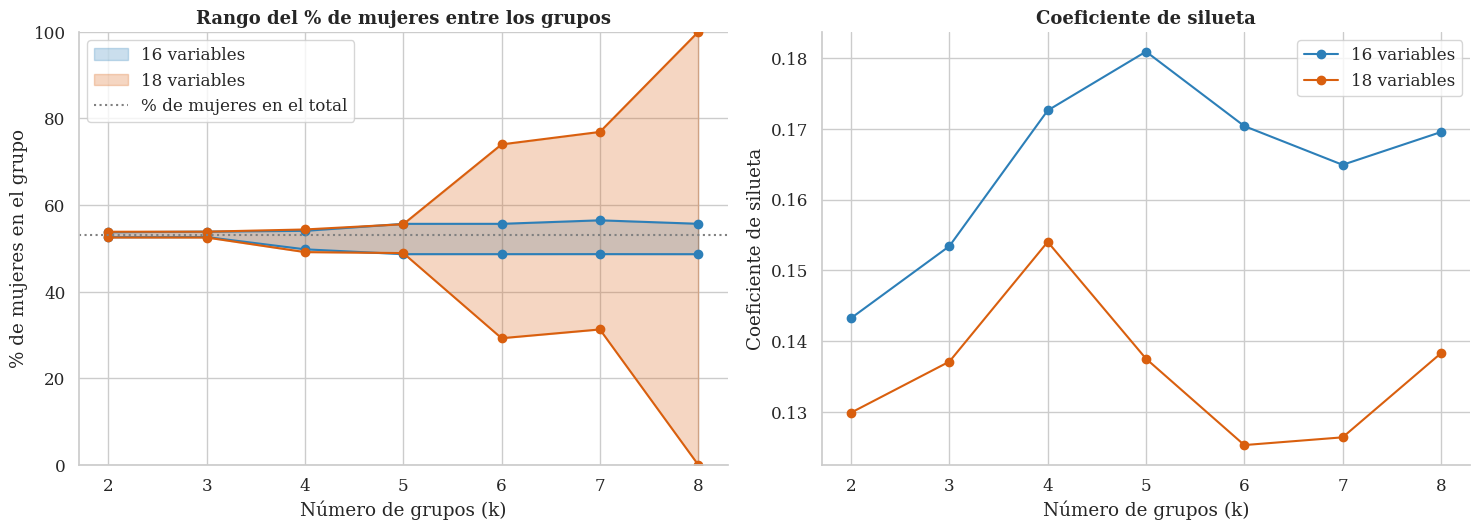

,Versión,k,Componentes,% mujeres mínimo,% mujeres máximo,Silueta
0,18 variables,2,20,52.505,53.834,0.130
1,18 variables,3,20,52.503,53.853,0.137
2,18 variables,4,20,49.130,54.362,0.154
3,18 variables,5,20,48.905,55.573,0.138
4,18 variables,6,20,29.238,74.017,0.125
5,18 variables,7,20,31.260,76.898,0.126
6,18 variables,8,20,0.000,100.000,0.138
7,16 variables,2,19,52.579,53.720,0.143
8,16 variables,3,19,52.609,53.863,0.153
9,16 variables,4,19,49.776,54.043,0.173


In [10]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
colores_version = {"18 variables": color_secundario, "16 variables": color_acento}

for nombre, datos in comparacion_variables.groupby("Versión"):
    color = colores_version[nombre]
    # Franja entre el grupo con menos mujeres y el grupo con más mujeres
    axes[0].fill_between(datos["k"], datos["% mujeres mínimo"], datos["% mujeres máximo"],
                         color=color, alpha=0.25, label=nombre)
    axes[0].plot(datos["k"], datos["% mujeres mínimo"], marker="o", color=color)
    axes[0].plot(datos["k"], datos["% mujeres máximo"], marker="o", color=color)
    axes[1].plot(datos["k"], datos["Silueta"], marker="o", color=color, label=nombre)

axes[0].axhline(es_mujer.mean() * 100, color="gray", linestyle=":", label="% de mujeres en el total")
axes[0].set_ylim(0, 100)
axes[0].set_xlabel("Número de grupos (k)")
axes[0].set_ylabel("% de mujeres en el grupo")
axes[0].set_title("Rango del % de mujeres entre los grupos", fontsize=13, fontweight="bold")

axes[1].set_xlabel("Número de grupos (k)")
axes[1].set_ylabel("Coeficiente de silueta")
axes[1].set_title("Coeficiente de silueta", fontsize=13, fontweight="bold")

for ax in axes:
    ax.set_xticks(range(2, 9))
    ax.legend(frameon=True)
sns.despine()
plt.tight_layout()
plt.show()

comparacion_variables.round(3)

**Resultados de la comprobación:**

- **Género:** con las 18 variables, hasta k = 5 todos los grupos tienen entre 49% y 56% de mujeres, cerca del 53% del total. Pero a partir de k = 6 el género empieza a separar a los estudiantes: con k = 6 hay grupos con 29% y 74% de mujeres, y con k = 8 aparece un grupo solo de hombres (0%) y otro solo de mujeres (100%). Con las 16 variables, en todos los k los grupos quedan entre 49% y 57% de mujeres.
- **Silueta:** las 16 variables tienen mayor silueta en todos los valores de k (entre 0.143 y 0.181, frente a 0.125 a 0.154 con las 18). Sin el género y el periodo, los grupos quedan más separados.

**Decisión:** se usan las **16 variables**. Con las 18, el género domina los grupos cuando k es mayor o igual a 6, lo que daría grupos separados por género y no por perfil socioeconómico y escolar. Además, las 16 variables forman grupos más separados para cualquier número de grupos.

In [11]:
# Variables elegidas según la comprobación
vars_cluster = vars_16
cols_cluster = [c for v in vars_cluster for c in cols_por_variable[v]]
Z_train, Z_test = preparar(vars_cluster)

print(f"Variables para los grupos: {len(vars_cluster)}")
print(f"Columnas para los grupos: {len(cols_cluster)}")
print(f"Train: {len(Z_train):,} estudiantes | Test: {len(Z_test):,} estudiantes")
print(f"Rango de las columnas: {Z_train.min().min():.0f} a {Z_train.max().max():.0f}")

Variables para los grupos: 16
Columnas para los grupos: 39
Train: 455,339 estudiantes | Test: 113,835 estudiantes
Rango de las columnas: 0 a 1


## **2. Reducción de dimensionalidad con PCA**

**Para qué se usa:**
1. **Ver qué resume cada componente**, revisando qué columnas pesan más en él.
2. **Visualizar** a los estudiantes en dos dimensiones.
3. **Preparar los datos para el clustering:** se conservan los componentes que explican el **90% de la varianza**. Así se eliminan direcciones que casi no aportan información (ruido) y el clustering es más rápido.

El PCA se ajusta solo con el entrenamiento y después se aplica a la prueba.

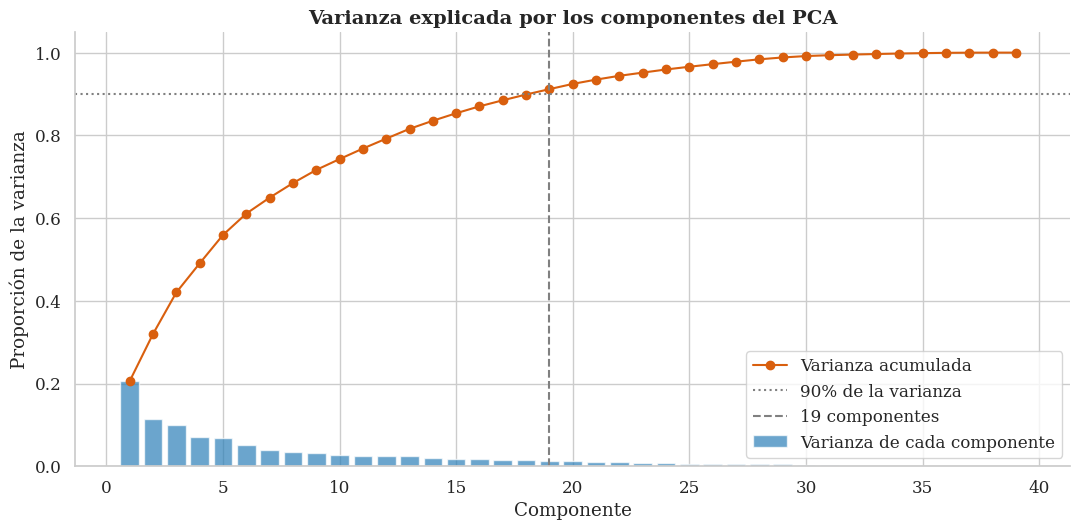

Componente 1: 20.6% | Componente 2: 11.4%
Componentes para el 90% de la varianza: 19 de 39


In [12]:
# PCA con todos los componentes para ver cuánta varianza explica cada uno
pca_completo = PCA(random_state=SEMILLA).fit(Z_train)
varianza = pca_completo.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza)

# Menor número de componentes que explica el 90% de la varianza
n_componentes = int(np.argmax(varianza_acumulada >= 0.90) + 1)

# Gráfico
fig, ax = plt.subplots(figsize=(11, 5.5))
posiciones = np.arange(1, len(varianza) + 1)
ax.bar(posiciones, varianza, color=color_acento, alpha=0.7, label="Varianza de cada componente")
ax.plot(posiciones, varianza_acumulada, marker="o", color=color_secundario,
        label="Varianza acumulada")
ax.axhline(0.90, color="gray", linestyle=":", label="90% de la varianza")
ax.axvline(n_componentes, color="gray", linestyle="--",
           label=f"{n_componentes} componentes")
ax.set_xlabel("Componente")
ax.set_ylabel("Proporción de la varianza")
ax.set_title("Varianza explicada por los componentes del PCA",
             fontsize=14, fontweight="bold")
ax.legend(frameon=True)
sns.despine()
plt.tight_layout()
plt.show()

print(f"Componente 1: {varianza[0]:.1%} | Componente 2: {varianza[1]:.1%}")
print(f"Componentes para el 90% de la varianza: {n_componentes} de {len(varianza)}")

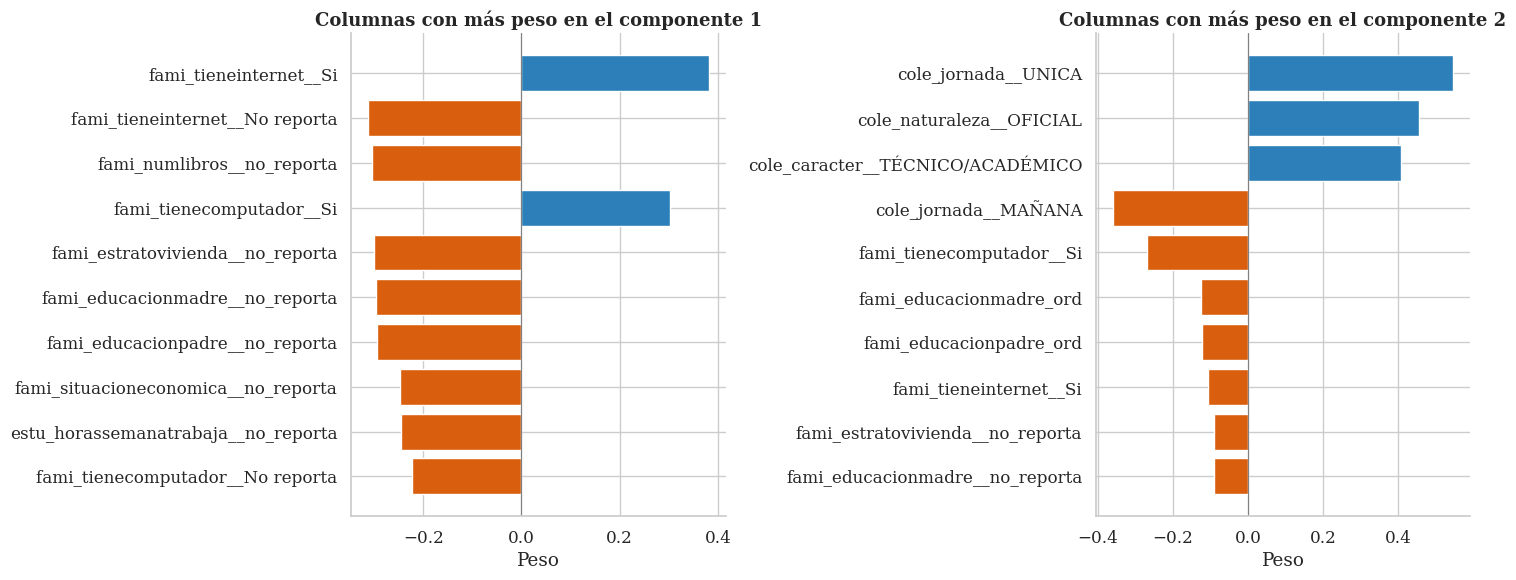

In [13]:
# Peso de cada columna en los dos primeros componentes
pesos = pd.DataFrame(pca_completo.components_[:2].T, index=cols_cluster,
                     columns=["Componente 1", "Componente 2"])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
for ax, componente in zip(axes, pesos.columns):
    principales = pesos[componente].sort_values(key=abs, ascending=False).head(10)
    colores = [color_acento if v > 0 else color_secundario for v in principales.values]
    ax.barh(principales.index, principales.values, color=colores)
    ax.axvline(0, color="gray", linewidth=0.8)
    ax.invert_yaxis()
    ax.set_title(f"Columnas con más peso en el {componente.lower()}",
                 fontsize=13, fontweight="bold")
    ax.set_xlabel("Peso")
sns.despine()
plt.tight_layout()
plt.show()

Correlación de Spearman del componente 1 con el puntaje: 0.318
Correlación de Spearman del componente 2 con el puntaje: -0.156


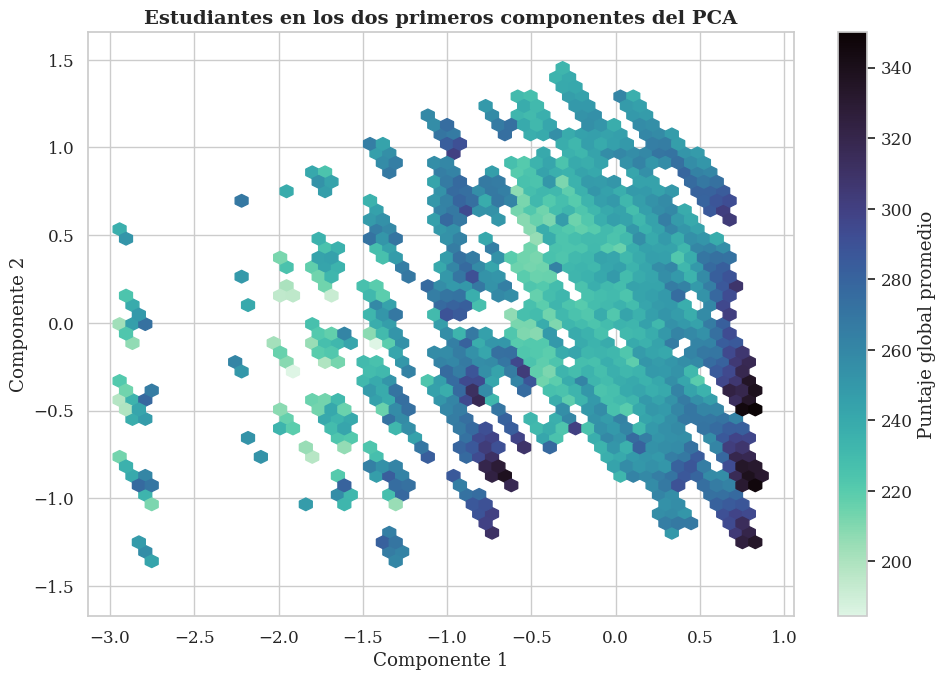

In [14]:
# Relación de los dos primeros componentes con el puntaje (que no se usó en el PCA)
componentes_train = pca_completo.transform(Z_train)[:, :2]

for i in range(2):
    rho = stats.spearmanr(componentes_train[:, i], y_train).statistic
    print(f"Correlación de Spearman del componente {i + 1} con el puntaje: {rho:.3f}")

# Estudiantes en los dos primeros componentes, coloreados por su puntaje promedio
fig, ax = plt.subplots(figsize=(10, 7))
hb = ax.hexbin(componentes_train[:, 0], componentes_train[:, 1], C=y_train,
               reduce_C_function=np.mean, gridsize=50, cmap="mako_r", mincnt=20)
ax.set_xlabel("Componente 1")
ax.set_ylabel("Componente 2")
ax.set_title("Estudiantes en los dos primeros componentes del PCA",
             fontsize=14, fontweight="bold")
fig.colorbar(hb, ax=ax, label="Puntaje global promedio")
plt.tight_layout()
plt.show()

**Resultados del PCA:**

- **Varianza explicada:** el componente 1 explica el 20.6% de la varianza y el componente 2 el 11.4% (32% entre los dos). Se necesitan 19 de los 39 componentes para llegar al 90%. La información está repartida entre muchas columnas, así que el gráfico de los dos primeros componentes es solo una vista parcial de los datos.
- **Componente 1:** las columnas con más peso son las indicadoras de "No reporta" de internet, libros, estrato, educación de los padres, situación económica, horas de trabajo y computador (peso negativo), y tener internet y computador (peso positivo). Este componente separa a los estudiantes que no responden las preguntas del hogar (a la izquierda) de los que responden y tienen internet y computador (a la derecha). Por eso en el gráfico se ven franjas separadas a la izquierda: son estudiantes que dejaron sin responder muchas, varias o algunas preguntas, porque los faltantes van en bloque.
- **Componente 2:** separa el tipo de colegio de los recursos del hogar. Pesan de forma positiva la jornada única, el colegio oficial y el carácter técnico/académico, y de forma negativa la jornada de la mañana, tener computador y la educación de los padres.
- **Relación con el puntaje:** el componente 1 tiene una correlación de 0.318 con el puntaje: los estudiantes que no responden sacan menos, igual que en el diagnóstico de faltantes de la entrega 2. El componente 2 tiene una correlación de −0.156: los estudiantes de colegios oficiales de jornada única y con menos recursos sacan menos. En el gráfico, los puntajes más altos están abajo a la derecha: estudiantes que responden todo, con internet, computador y padres con más educación.

**Conclusión:** el PCA confirma que no responder las preguntas del hogar es una de las características que más diferencia a los estudiantes, y que se relaciona con un menor puntaje, como se encontró en la entrega 2. La educación de los padres, que era la variable más relacionada con el puntaje según Spearman y η², aparece en el segundo componente y no en el primero: diferencia a los estudiantes menos que el bloque de respuestas "No reporta". Al interpretar los grupos de K-means hay que tener en cuenta que puede aparecer un grupo de estudiantes sin información del hogar.

In [15]:
# Datos reducidos con los componentes que explican el 90% de la varianza
pca = PCA(n_components=n_componentes, random_state=SEMILLA).fit(Z_train)
P_train = pca.transform(Z_train)
P_test = pca.transform(Z_test)

print(f"Datos para el clustering: {P_train.shape[1]} componentes en lugar de {Z_train.shape[1]} columnas")

Datos para el clustering: 19 componentes en lugar de 39 columnas


## **3. Clustering con K-means: elección del número de grupos**

K-means necesita que se le diga el número de grupos, así que *k* se elige con dos criterios, probando *k* = 2, …, 10:

1. **Método del codo**
2. **Coeficiente de silueta**

**Decisiones:**
- Se usan las mismas muestras de la comprobación del paso 1: **100 mil estudiantes** del entrenamiento para el codo y **20 mil** para la silueta, porque la silueta compara cada estudiante con todos los demás y con todo el entrenamiento sería muy lenta.

In [16]:
filas = []
for k in range(2, 11):
    kmeans_k = KMeans(n_clusters=k, n_init=1, random_state=SEMILLA).fit(P_train[i_muestra])
    silueta = silhouette_score(P_train[i_silueta], kmeans_k.predict(P_train[i_silueta]))
    filas.append({"k": k, "inercia": kmeans_k.inertia_, "silueta": silueta})
    print(f"k={k:2d} | inercia = {kmeans_k.inertia_:,.0f} | silueta = {silueta:.3f}")

eleccion_k = pd.DataFrame(filas)

k= 2 | inercia = 266,339 | silueta = 0.143
k= 3 | inercia = 219,107 | silueta = 0.151
k= 4 | inercia = 196,148 | silueta = 0.166
k= 5 | inercia = 184,150 | silueta = 0.165
k= 6 | inercia = 175,008 | silueta = 0.159
k= 7 | inercia = 160,531 | silueta = 0.171
k= 8 | inercia = 153,270 | silueta = 0.172
k= 9 | inercia = 150,982 | silueta = 0.178
k=10 | inercia = 147,286 | silueta = 0.170


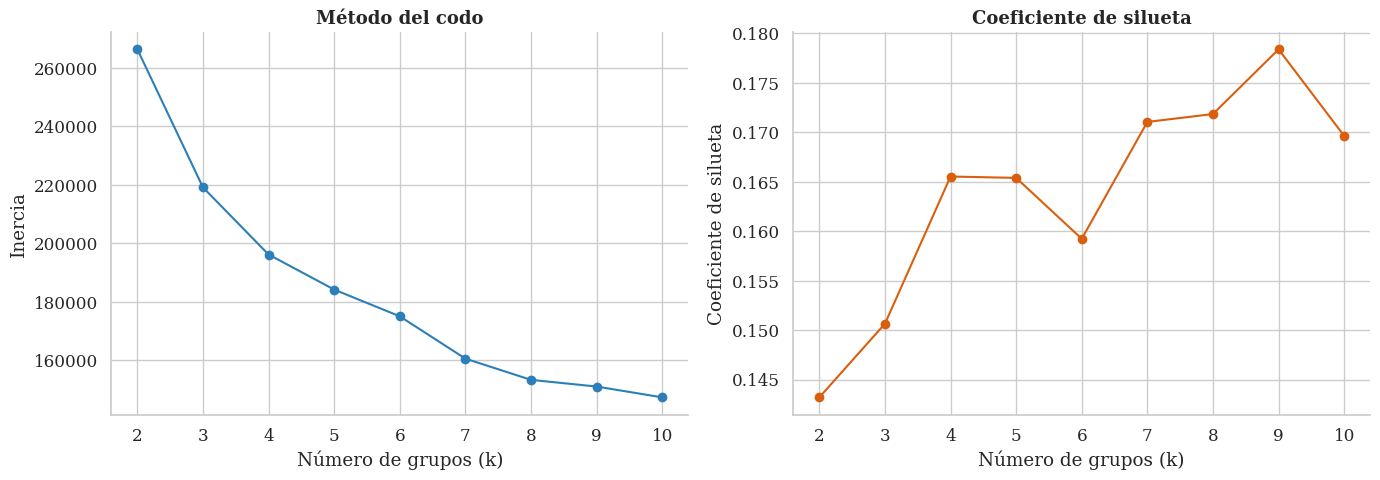

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(eleccion_k["k"], eleccion_k["inercia"], marker="o", color=color_acento)
axes[0].set_xlabel("Número de grupos (k)")
axes[0].set_ylabel("Inercia")
axes[0].set_title("Método del codo", fontsize=13, fontweight="bold")

axes[1].plot(eleccion_k["k"], eleccion_k["silueta"], marker="o", color=color_secundario)
axes[1].set_xlabel("Número de grupos (k)")
axes[1].set_ylabel("Coeficiente de silueta")
axes[1].set_title("Coeficiente de silueta", fontsize=13, fontweight="bold")

for ax in axes:
    ax.set_xticks(eleccion_k["k"])
sns.despine()
plt.tight_layout()
plt.show()

**Resultados de la elección de k:**

- **Codo:** la inercia baja mucho de k = 2 a k = 3 (47 mil) y de k = 3 a k = 4 (23 mil). A partir de k = 4 cada grupo nuevo la reduce mucho menos (12 mil de 4 a 5 y 9 mil de 5 a 6), así que el codo está en k = 4.
- **Silueta:** el mayor aumento ocurre de k = 3 (0.151) a k = 4 (0.166), y se mantiene en k = 5 (0.165). La silueta más alta es con k = 9 (0.178), pero solo supera a k = 4 en 0.012. En todos los casos la silueta es menor a 0.25: los grupos se traslapan, lo que es esperable porque los perfiles socioeconómicos cambian de forma gradual y no en grupos claramente separados.

**Número de grupos elegido:** k = 4. Coincide con el codo y con el mayor aumento de la silueta. Usar más grupos casi no mejora la silueta y haría más difícil describir e interpretar los perfiles.

In [18]:
# Número de grupos elegido con el codo y la silueta
n_grupos = 4

## **4. Perfiles de los grupos**

* Se entrena K-means con el número de grupos elegido y con **todo el
entrenamiento**. Después, cada estudiante de la prueba se asigna al grupo cuyo centro le queda más cerca.

* Para que los grupos sean fáciles de leer, se numeran de menor a mayor puntaje promedio: el grupo 1 es el de menor puntaje. El puntaje solo se usa para ponerles número, no para formarlos.

* Cada grupo se describe con el porcentaje de estudiantes que tiene cada característica, usando las respuestas originales.

In [19]:
kmeans = KMeans(n_clusters=n_grupos, n_init=1, random_state=SEMILLA).fit(P_train)

# Numerar los grupos de menor a mayor puntaje promedio
puntaje_por_grupo = y_train.groupby(kmeans.labels_).mean().sort_values()
numero_grupo = {grupo: i + 1 for i, grupo in enumerate(puntaje_por_grupo.index)}

grupo_train = pd.Series(kmeans.labels_, index=X_train.index).map(numero_grupo)
grupo_test = pd.Series(kmeans.predict(P_test), index=X_test.index).map(numero_grupo)

print("Estudiantes por grupo (entrenamiento):")
print(grupo_train.value_counts().sort_index().to_string())

Estudiantes por grupo (entrenamiento):
1     43001
2    144430
3    116783
4    151125


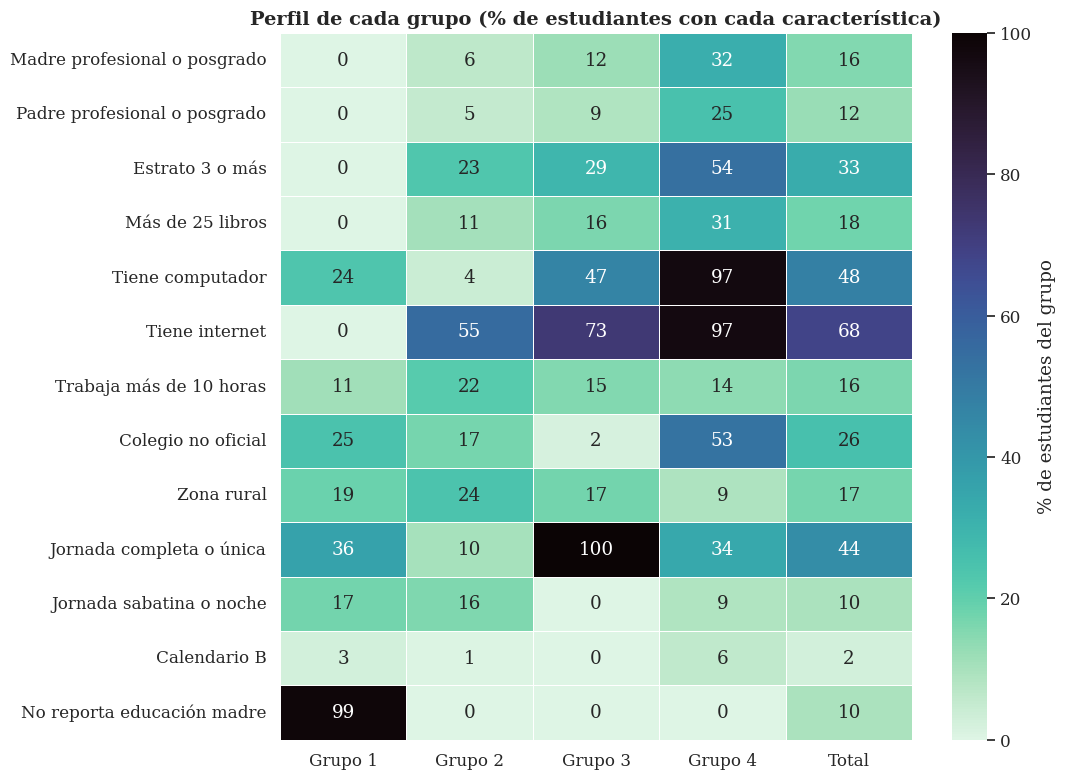

In [20]:
# Características de cada estudiante con sus respuestas originales
def caracteristicas(datos):
    educacion_alta = ["Educación profesional completa", "Postgrado"]
    return pd.DataFrame({
        "Madre profesional o posgrado": datos["fami_educacionmadre"].isin(educacion_alta),
        "Padre profesional o posgrado": datos["fami_educacionpadre"].isin(educacion_alta),
        "Estrato 3 o más": datos["fami_estratovivienda"].isin([f"Estrato {i}" for i in range(3, 7)]),
        "Más de 25 libros": datos["fami_numlibros"].isin(["26 A 100 LIBROS", "MÁS DE 100 LIBROS"]),
        "Tiene computador": datos["fami_tienecomputador"] == "Si",
        "Tiene internet": datos["fami_tieneinternet"] == "Si",
        "Trabaja más de 10 horas": datos["estu_horassemanatrabaja"].isin(
            ["Entre 11 y 20 horas", "Entre 21 y 30 horas", "Más de 30 horas"]),
        "Colegio no oficial": datos["cole_naturaleza"] == "NO OFICIAL",
        "Zona rural": datos["cole_area_ubicacion"] == "RURAL",
        "Jornada completa o única": datos["cole_jornada"].isin(["COMPLETA", "UNICA"]),
        "Jornada sabatina o noche": datos["cole_jornada"].isin(["SABATINA", "NOCHE"]),
        "Calendario B": datos["cole_calendario"] == "B",
        "No reporta educación madre": datos["fami_educacionmadre"] == "No reporta",
    }).astype(int)

rasgos_train = caracteristicas(df.loc[X_train.index])

# Porcentaje de estudiantes con cada característica en cada grupo
perfiles = (rasgos_train.groupby(grupo_train).mean() * 100).T
perfiles.columns = [f"Grupo {g}" for g in perfiles.columns]
perfiles["Total"] = rasgos_train.mean() * 100

# Gráfico
fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(perfiles, annot=True, fmt=".0f", cmap="mako_r", vmin=0, vmax=100,
            linewidths=0.6, linecolor="white",
            cbar_kws={"label": "% de estudiantes del grupo"}, ax=ax)
ax.set_title("Perfil de cada grupo (% de estudiantes con cada característica)",
             fontsize=14, fontweight="bold")
ax.set_ylabel("")
plt.tight_layout()
plt.show()

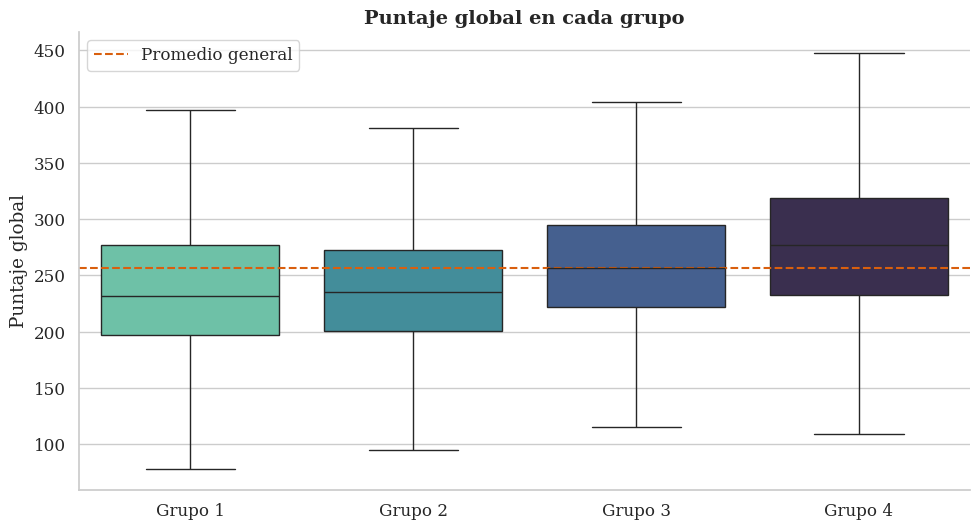

,Estudiantes,% del total,Puntaje promedio,Puntaje mediana,Desv. estándar
Grupo 1,43001,9.4,238.8,232.0,53.6
Grupo 2,144430,31.7,239.8,235.0,49.7
Grupo 3,116783,25.6,259.1,257.0,49.9
Grupo 4,151125,33.2,276.2,277.0,57.1


In [21]:
# Tamaño y puntaje de cada grupo
resumen_grupos = pd.DataFrame({
    "Estudiantes": grupo_train.value_counts().sort_index(),
    "% del total": grupo_train.value_counts(normalize=True).sort_index() * 100,
    "Puntaje promedio": y_train.groupby(grupo_train).mean(),
    "Puntaje mediana": y_train.groupby(grupo_train).median(),
    "Desv. estándar": y_train.groupby(grupo_train).std(),
})
resumen_grupos.index = [f"Grupo {g}" for g in resumen_grupos.index]

# Distribución del puntaje en cada grupo
fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(x=grupo_train.map(lambda g: f"Grupo {g}"), y=y_train,
            order=resumen_grupos.index, hue=grupo_train.map(lambda g: f"Grupo {g}"),
            palette="mako", legend=False, showfliers=False, ax=ax)
ax.axhline(y_train.mean(), color=color_secundario, linestyle="--", label="Promedio general")
ax.set_xlabel("")
ax.set_ylabel("Puntaje global")
ax.set_title("Puntaje global en cada grupo", fontsize=14, fontweight="bold")
ax.legend(frameon=True)
sns.despine()
plt.tight_layout()
plt.show()

resumen_grupos.round(1)

**Resultados de los perfiles:**

- **Grupo 1, sin información del hogar** (9.4% de los estudiantes, puntaje promedio 238.8): el 99% no reporta la educación de la madre, y ninguno reporta tener internet, estrato 3 o más, más de 25 libros o padres profesionales. Es el grupo de estudiantes que no responde las preguntas del hogar, el mismo que separa el componente 1 del PCA. Por el tipo de colegio se parece al total (25% no oficial), aunque tiene más estudiantes de jornada sabatina o noche (17%).
- **Grupo 2, oficial con pocos recursos** (31.7%, puntaje promedio 239.8): solo el 4% tiene computador y el 55% internet, el 6% tiene madre profesional y el 23% estrato 3 o más. Es el grupo con más estudiantes de zona rural (24%) y que más trabajan más de 10 horas (22%). Casi todos estudian en colegios oficiales (17% no oficial) y pocos en jornada completa o única (10%).
- **Grupo 3, oficial de jornada única** (25.6%, puntaje promedio 259.1): el 100% estudia en jornada completa o única y casi todos en colegios oficiales (2% no oficial). Tiene recursos intermedios: el 47% tiene computador, el 73% internet y el 12% madre profesional.
- **Grupo 4, hogares con más recursos** (33.2%, puntaje promedio 276.2): el 97% tiene computador e internet, el 54% es de estrato 3 o más, el 32% tiene madre profesional y el 31% más de 25 libros. Es el único grupo con mayoría de colegios no oficiales (53%) y el que tiene menos estudiantes rurales (9%).

**Relación con el puntaje:** el grupo 4 saca en promedio 37 puntos más que el grupo 1 (276.2 frente a 238.8). Los grupos 1 y 2 tienen casi el mismo puntaje (238.8 y 239.8), aunque por razones distintas: uno no tiene información del hogar y el otro tiene pocos recursos. Sin embargo, la desviación estándar dentro de cada grupo (entre 50 y 57 puntos) es mayor que la diferencia entre grupos, así que los puntajes se traslapan mucho en el boxplot: hay estudiantes del grupo 1 con puntajes altos y del grupo 4 con puntajes bajos.

**Interpretación:** los grupos se separan por tres cosas: si el estudiante responde o no las preguntas del hogar (grupo 1), los recursos del hogar (computador, internet, estrato, educación de los padres) y el tipo de colegio (oficial o no oficial, jornada única o no). El grupo 3 muestra que, entre estudiantes de colegios oficiales, los de jornada única y con algo más de recursos sacan 19 puntos más que los del grupo 2.

## **5. Grupos por región y tipo de colegio**

Se revisa cómo se reparten en los grupos los estudiantes de Santander frente al resto del país, de colegios oficiales frente a no oficiales, y de zona urbana frente a rural (objetivos 2 y 3). Si un tipo de estudiante se concentra en ciertos grupos, sus diferencias de puntaje pueden deberse a su perfil y no solo a la región o al tipo de colegio.

Como el departamento no se usó para formar los grupos, esta comparación muestra si Santander tiene un perfil de estudiantes distinto al del resto del país.

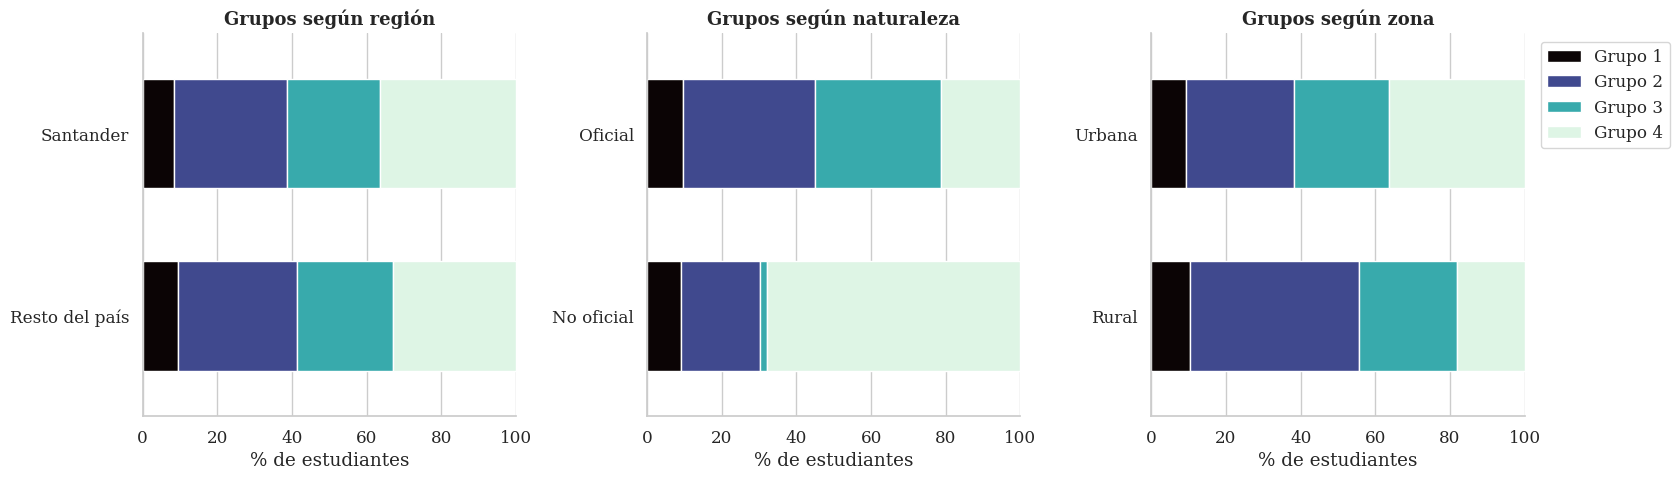


Región (% de estudiantes en cada grupo):
                Grupo 1  Grupo 2  Grupo 3  Grupo 4
row_0                                             
Resto del país      9.5     31.8     25.7     33.0
Santander           8.5     30.1     24.8     36.6

Naturaleza (% de estudiantes en cada grupo):
                 Grupo 1  Grupo 2  Grupo 3  Grupo 4
cole_naturaleza                                    
No oficial           9.2     21.2      1.7     68.0
Oficial              9.5     35.4     33.9     21.2

Zona (% de estudiantes en cada grupo):
                     Grupo 1  Grupo 2  Grupo 3  Grupo 4
cole_area_ubicacion                                    
Rural                   10.4     45.3     26.1     18.2
Urbana                   9.3     28.9     25.5     36.3


In [22]:
datos_train = df.loc[X_train.index]

# Grupos de comparación
comparaciones = {
    "Región": np.where(datos_train["cole_depto_ubicacion"].str.upper() == "SANTANDER",
                       "Santander", "Resto del país"),
    "Naturaleza": datos_train["cole_naturaleza"].str.capitalize(),
    "Zona": datos_train["cole_area_ubicacion"].str.capitalize(),
}

fig, axes = plt.subplots(1, 3, figsize=(17, 5))
tablas_composicion = {}
for ax, (nombre, valores) in zip(axes, comparaciones.items()):
    # Porcentaje de cada tipo de estudiante que cae en cada grupo
    tabla = pd.crosstab(valores, grupo_train.to_numpy(), normalize="index") * 100
    tabla.columns = [f"Grupo {g}" for g in tabla.columns]
    tablas_composicion[nombre] = tabla

    tabla.plot(kind="barh", stacked=True, ax=ax, colormap="mako", width=0.6, legend=False)
    ax.set_title(f"Grupos según {nombre.lower()}", fontsize=13, fontweight="bold")
    ax.set_xlabel("% de estudiantes")
    ax.set_ylabel("")
    ax.set_xlim(0, 100)

axes[-1].legend(title="", frameon=True, bbox_to_anchor=(1.02, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

for nombre, tabla in tablas_composicion.items():
    print(f"\n{nombre} (% de estudiantes en cada grupo):")
    print(tabla.round(1).to_string())

In [23]:
# Puntaje promedio de Santander y del resto del país dentro de cada grupo
region = pd.Series(comparaciones["Región"], index=X_train.index)
puntaje_region = y_train.groupby([grupo_train, region]).mean().unstack()
puntaje_region.index = [f"Grupo {g}" for g in puntaje_region.index]
puntaje_region["Diferencia"] = puntaje_region["Santander"] - puntaje_region["Resto del país"]

print("Puntaje promedio por grupo y región:")
puntaje_region.round(1)

Puntaje promedio por grupo y región:


,Resto del país,Santander,Diferencia
Grupo 1,237.9,261.3,23.5
Grupo 2,239.1,256.3,17.2
Grupo 3,258.6,269.9,11.3
Grupo 4,275.3,292.4,17.1


**Resultados por región y tipo de colegio:**

- **Santander frente al resto del país:** Santander tiene un poco más de estudiantes en el grupo con más recursos (36.6% en el grupo 4, frente a 33.0% en el resto del país) y un poco menos en los grupos 1 y 2. La diferencia es pequeña: el perfil de los estudiantes de Santander se parece al del resto del país.
- **Dentro de cada grupo:** Santander saca más puntaje que el resto del país en los cuatro grupos, entre 11.3 y 23.5 puntos más. La mayor diferencia está en el grupo 1 (261.3 frente a 237.9) y la menor en el grupo 3 (269.9 frente a 258.6). Como la diferencia se mantiene al comparar estudiantes con el mismo perfil, no se explica solo por el perfil socioeconómico y escolar: hay algo propio de Santander que el modelo no conoce, porque el departamento no es una variable del modelo. Esto se analiza en el objetivo 2.
- **Oficial y no oficial:** el 68% de los estudiantes de colegios no oficiales está en el grupo 4, el de más recursos. Los de colegios oficiales se reparten sobre todo entre los grupos 2 (35.4%) y 3 (33.9%), y solo el 21.2% está en el grupo 4.
- **Urbano y rural:** el 45.3% de los estudiantes rurales está en el grupo 2, el de menos recursos, y solo el 18.2% en el grupo 4. En la zona urbana, el grupo más común es el 4 (36.3%). El grupo 1 tiene casi la misma proporción en las dos zonas (10.4% y 9.3%).

## **6. Error del modelo en cada grupo**

Se entrena de nuevo el modelo final de la entrega 2 (HistGradientBoosting optimizado, con las 18 variables y todo el entrenamiento) y se mide su error en el conjunto de prueba **para cada grupo**. Así se responde si el modelo predice igual de bien para todos los perfiles de estudiantes.

**Métricas por grupo:**
- **RMSE y MAE:** qué tanto se equivoca el modelo en promedio.
- **Error promedio** (puntaje real − predicho): si es positivo, el modelo predice de menos para ese grupo; si es negativo, predice de más.
- **R² dentro del grupo:** qué parte de las diferencias de puntaje *entre estudiantes del mismo grupo* explica el modelo. Es más bajo que el R² general porque dentro de un grupo los estudiantes se parecen más entre sí.

In [24]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

hgb_final = HistGradientBoostingRegressor(**mejores_params, max_iter=500,
                                          early_stopping=True, random_state=SEMILLA)
hgb_final.fit(X_train[cols_seleccionadas], y_train)
prediccion_test = pd.Series(hgb_final.predict(X_test[cols_seleccionadas]), index=X_test.index)

print(f"RMSE general en el test: {mean_squared_error(y_test, prediccion_test) ** 0.5:.2f}")

# Métricas del modelo en cada grupo
filas = []
for g in sorted(grupo_test.unique()):
    en_grupo = grupo_test == g
    real, pred = y_test[en_grupo], prediccion_test[en_grupo]
    filas.append({
        "Grupo": f"Grupo {g}",
        "Estudiantes test": en_grupo.sum(),
        "Puntaje real promedio": real.mean(),
        "Puntaje predicho promedio": pred.mean(),
        "Error promedio": (real - pred).mean(),
        "RMSE": mean_squared_error(real, pred) ** 0.5,
        "MAE": mean_absolute_error(real, pred),
        "R2 dentro del grupo": r2_score(real, pred),
    })

error_por_grupo = pd.DataFrame(filas).set_index("Grupo").round(3)
error_por_grupo

RMSE general en el test: 44.18


,Estudiantes test,Puntaje real promedio,Puntaje predicho promedio,Error promedio,RMSE,MAE,R2 dentro del grupo
Grupo,,,,,,,
Grupo 1,10743,239.655,238.852,0.804,45.690,36.905,0.285
Grupo 2,36052,240.086,239.871,0.214,42.031,33.765,0.280
Grupo 3,29492,259.114,259.166,-0.052,44.906,36.552,0.197
Grupo 4,37548,276.047,276.268,-0.221,45.167,36.392,0.374


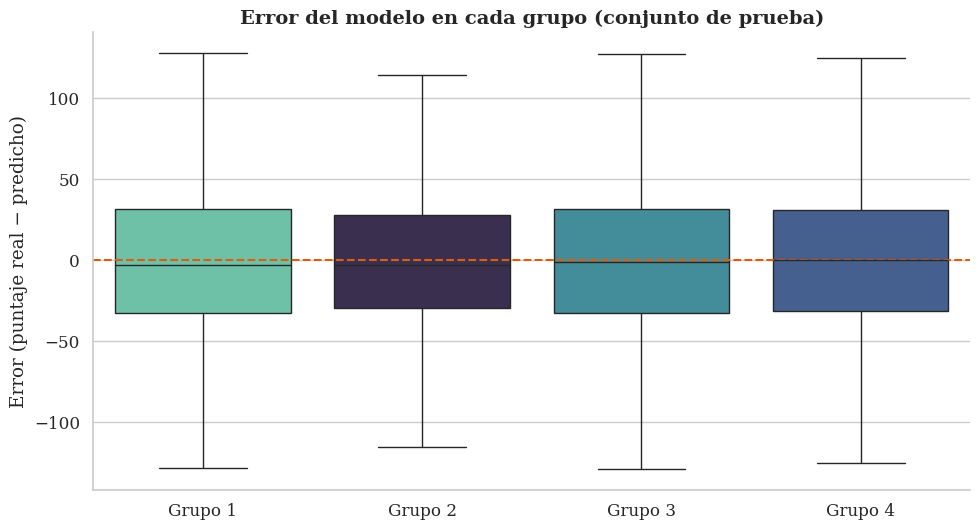

In [25]:
# Error de predicción de cada estudiante del test (positivo: el modelo predijo de menos)
errores = y_test - prediccion_test

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.boxplot(x=grupo_test.map(lambda g: f"Grupo {g}"), y=errores,
            order=error_por_grupo.index, hue=grupo_test.map(lambda g: f"Grupo {g}"),
            palette="mako", legend=False, showfliers=False, ax=ax)
ax.axhline(0, color=color_secundario, linestyle="--")
ax.set_xlabel("")
ax.set_ylabel("Error (puntaje real − predicho)")
ax.set_title("Error del modelo en cada grupo (conjunto de prueba)",
             fontsize=14, fontweight="bold")
sns.despine()
plt.tight_layout()
plt.show()

**Resultados del error por grupo:**

- **RMSE por grupo:** el modelo se equivoca más en el grupo 1 (45.69), el de estudiantes sin información del hogar, y menos en el grupo 2 (42.03). Los grupos 3 y 4 están cerca del RMSE general (44.91 y 45.17 frente a 44.18). La diferencia entre el grupo con más y menos error es de 3.7 puntos, pequeña frente al tamaño del error.
- **Error promedio:** está entre −0.22 y 0.80 puntos en todos los grupos, prácticamente 0. El modelo no predice de más ni de menos para ningún perfil, y el puntaje predicho promedio de cada grupo es casi igual al real.
- **R² dentro del grupo:** es mayor en el grupo 4 (0.374) y menor en el grupo 3 (0.197). En los grupos 1 y 2 es 0.285 y 0.280. En el grupo 3 los estudiantes se parecen mucho entre sí (todos de colegios oficiales de jornada única), así que el modelo tiene poca información para distinguir quién saca más o menos dentro del grupo.

**Interpretación:** el modelo generaliza de forma parecida para todos los perfiles: el error es similar entre grupos y no tiene sesgo en ninguno. El grupo menos confiable es el 1, lo que es esperable porque el modelo no tiene información de su hogar.

## **7. Comparación con Agglomerative Clustering y DBSCAN**

**Agglomerative Clustering:** empieza con cada estudiante como un grupo y en cada paso une los dos grupos más parecidos, hasta que queda uno solo. El resultado se muestra en un **dendrograma**. Necesita calcular la distancia entre todos los pares de estudiantes, así que con los 455 mil del entrenamiento no cabe en memoria. Se usa solo como comparación.

**DBSCAN:** forma grupos con las zonas donde hay muchos estudiantes juntos (alta densidad) y marca como ruido a los que quedan aislados. No necesita el número de grupos, pero sí dos parámetros: `eps` (la distancia máxima para considerar que dos estudiantes son vecinos) y `min_samples` (cuántos vecinos se necesitan para formar una zona densa).

**Comparación con K-means:**
- **Coeficiente de silueta** de cada método en la misma muestra, para ver cuál forma grupos más separados.
- **Cruce de grupos** entre K-means y Agglomerative en un mapa de calor, para ver si los dos métodos ponen juntos a los mismos estudiantes.
- En DBSCAN, el número de grupos, el % de ruido y el % de estudiantes en el grupo más grande para varios valores de `eps`.

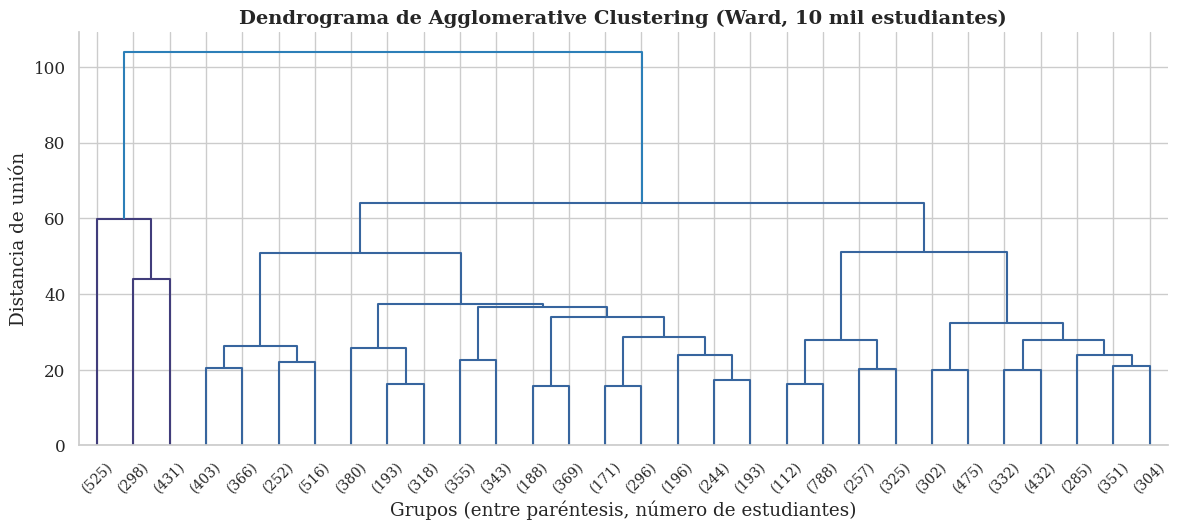

Silueta K-means: 0.164
Silueta Agglomerative: 0.128


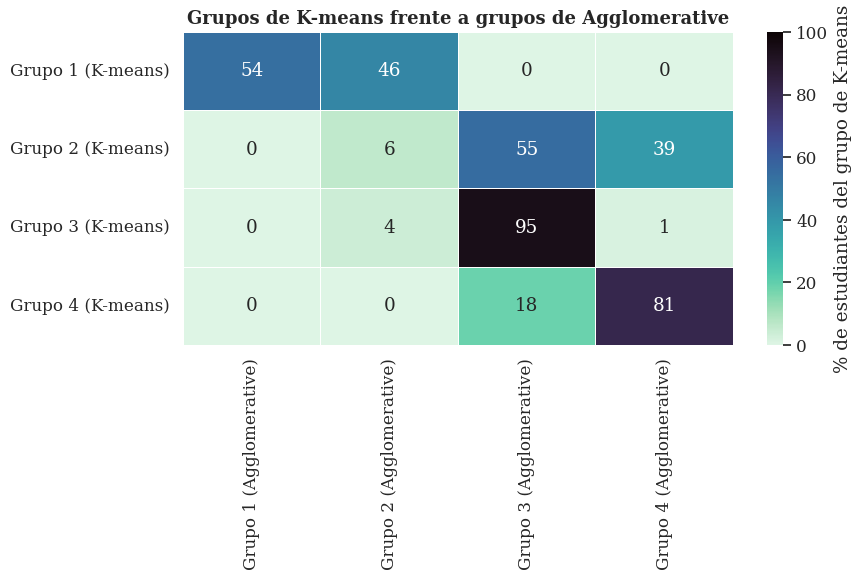

In [26]:
from scipy.cluster.hierarchy import linkage, dendrogram
from sklearn.cluster import AgglomerativeClustering
# Muestra de 10 mil estudiantes y su grupo de K-means
i_comparacion = i_muestra[:10_000]
P_comparacion = P_train[i_comparacion]
grupo_kmeans = grupo_train.to_numpy()[i_comparacion]

# Dendrograma con el enlace de Ward
uniones = linkage(P_comparacion, method="ward")

fig, ax = plt.subplots(figsize=(12, 5.5))
dendrogram(uniones, truncate_mode="lastp", p=30, color_threshold=None,
           above_threshold_color=color_acento, ax=ax)
ax.set_xlabel("Grupos (entre paréntesis, número de estudiantes)")
ax.set_ylabel("Distancia de unión")
ax.set_title("Dendrograma de Agglomerative Clustering",
             fontsize=14, fontweight="bold")
sns.despine()
plt.tight_layout()
plt.show()

# Mismo número de grupos que K-means
aglomerativo = AgglomerativeClustering(n_clusters=n_grupos, linkage="ward").fit(P_comparacion)

print(f"Silueta K-means: {silhouette_score(P_comparacion, grupo_kmeans):.3f}")
print(f"Silueta Agglomerative: {silhouette_score(P_comparacion, aglomerativo.labels_):.3f}")

# Numerar los grupos de Agglomerative de menor a mayor puntaje promedio, igual que en K-means
puntaje_comparacion = y_train.to_numpy()[i_comparacion]
orden_aglomerativo = pd.Series(puntaje_comparacion).groupby(aglomerativo.labels_).mean().sort_values().index
grupo_aglomerativo = pd.Series(aglomerativo.labels_).map(
    {grupo: i + 1 for i, grupo in enumerate(orden_aglomerativo)}).to_numpy()

# Cómo se reparten los grupos de K-means entre los grupos de Agglomerative
cruce_metodos = pd.crosstab(pd.Series(grupo_kmeans).map(lambda g: f"Grupo {g} (K-means)"),
                            pd.Series(grupo_aglomerativo).map(lambda g: f"Grupo {g} (Agglomerative)"),
                            normalize="index") * 100

plt.figure(figsize=(9, 6))
sns.heatmap(cruce_metodos, annot=True, fmt=".0f", cmap="mako_r", vmin=0, vmax=100,
            linewidths=0.6, linecolor="white",
            cbar_kws={"label": "% de estudiantes del grupo de K-means"})
plt.title("Grupos de K-means frente a grupos de Agglomerative",
          fontsize=13, fontweight="bold")
plt.xlabel("")
plt.ylabel("")
plt.tight_layout()
plt.show()

% de estudiantes con exactamente las mismas respuestas que otro: 8.3%



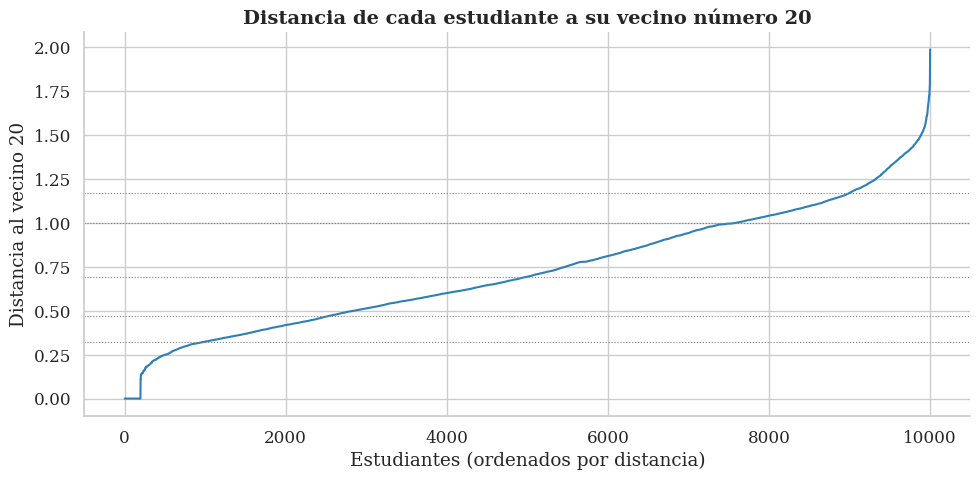

,eps,Grupos,% ruido,% en el grupo más grande
0,0.32,22,82.07,16.79
1,0.47,42,63.33,11.04
2,0.69,72,35.77,9.84
3,1.00,5,10.68,90.25
4,1.17,5,1.51,87.93


In [27]:
from sklearn.cluster import DBSCAN
from sklearn.neighbors import NearestNeighbors

min_vecinos = 20

# Distancia de cada estudiante a su vecino número 20, ordenada de menor a mayor
distancias, _ = NearestNeighbors(n_neighbors=min_vecinos).fit(P_comparacion).kneighbors(P_comparacion)
distancia_k = np.sort(distancias[:, -1])

# Estudiantes que quedan en el mismo punto que otros (mismas respuestas)
repetidos = pd.DataFrame(P_comparacion).round(6).duplicated(keep=False).mean()
print(f"% de estudiantes con exactamente las mismas respuestas que otro: {repetidos:.1%}\n")

# DBSCAN con varios valores de eps tomados de la curva de distancias
filas = []
for percentil in [10, 25, 50, 75, 90]:
    eps = np.percentile(distancia_k, percentil)
    dbscan = DBSCAN(eps=eps, min_samples=min_vecinos).fit(P_comparacion)
    etiquetas = dbscan.labels_
    filas.append({
        "eps": round(eps, 3),
        "Grupos": len(set(etiquetas)) - (1 if -1 in etiquetas else 0),
        "% ruido": (etiquetas == -1).mean() * 100,
        "% en el grupo más grande": pd.Series(etiquetas[etiquetas != -1]).value_counts(normalize=True).max() * 100
            if (etiquetas != -1).any() else 0,
    })

resultados_dbscan = pd.DataFrame(filas).round(2)

# Gráfico de la curva de distancias
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(distancia_k, color=color_acento)
for eps in resultados_dbscan["eps"]:
    ax.axhline(eps, color="gray", linestyle=":", linewidth=0.8)
ax.set_xlabel("Estudiantes (ordenados por distancia)")
ax.set_ylabel(f"Distancia al vecino {min_vecinos}")
ax.set_title("Distancia de cada estudiante a su vecino número 20",
             fontsize=14, fontweight="bold")
sns.despine()
plt.tight_layout()
plt.show()

resultados_dbscan

**Resultados de la comparación:**

- **Agglomerative Clustering:** su silueta es menor que la de K-means en la misma muestra (0.128 frente a 0.164), así que forma grupos menos separados. En el mapa de calor, los dos métodos coinciden en parte: el 95% del grupo 3 de K-means queda en un mismo grupo de Agglomerative, y el 81% del grupo 4 también. Pero Agglomerative divide en dos el grupo 1 de K-means (54% y 46%) y reparte el grupo 2 entre los grupos de Agglomerative que corresponden a los grupos 3 y 4 de K-means (55% y 39%). En el dendrograma, la unión más alta (distancia de unos 104) separa un grupo pequeño de los demás, que corresponde a los estudiantes sin información del hogar. Cortando por debajo de las siguientes uniones (distancias de 64 y 51) quedan 4 grupos, el mismo número elegido con K-means.
- **DBSCAN:** con eps pequeños (0.32 a 0.69) forma muchos grupos (entre 22 y 72) y deja como ruido entre el 36% y el 82% de los estudiantes. Con eps más grandes (1.00 y 1.17) forma 5 grupos, pero casi todos los estudiantes (entre 88% y 90%) quedan en uno solo. Ningún valor de eps da grupos útiles. Esto se debe a que casi todas las variables son categóricas: el 8.3% de la muestra tiene exactamente las mismas respuestas que otro estudiante y queda en el mismo punto, así que la densidad cambia de forma brusca.

**Conclusión:** se conserva **K-means**. Tiene mayor silueta que Agglomerative Clustering, y los dos métodos encuentran el mismo número de grupos y coinciden en los grupos 3 y 4. Además, es el único de los tres que puede entrenarse con todo el entrenamiento, y permite asignar a los estudiantes de la prueba a un grupo, lo que se necesita para medir el error del modelo por grupo.

## **8. Visualización con t-SNE**


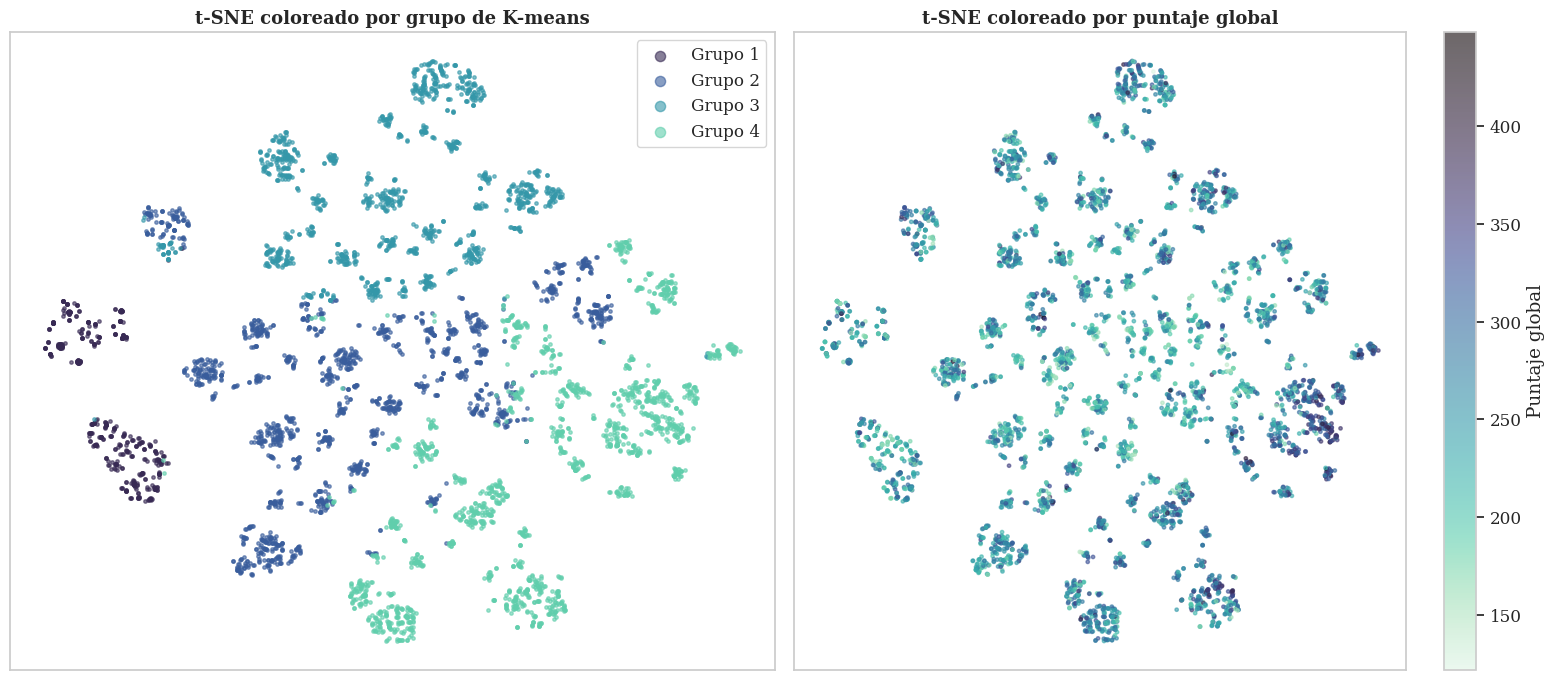

In [30]:
from sklearn.manifold import TSNE

# Muestra de 5 mil estudiantes del entrenamiento (Para evitar el colapso en Colab)
i_tsne = i_muestra[:5_000]

tsne = TSNE(n_components=2, perplexity=30, init="pca", random_state=SEMILLA)
T = tsne.fit_transform(P_train[i_tsne])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))

# Coloreado por grupo de K-means
grupos_tsne = grupo_train.to_numpy()[i_tsne]
for g in sorted(np.unique(grupos_tsne)):
    en_grupo = grupos_tsne == g
    axes[0].scatter(T[en_grupo, 0], T[en_grupo, 1], s=6, alpha=0.6, label=f"Grupo {g}",
                    color=sns.color_palette("mako", n_grupos)[g - 1])
axes[0].set_title("t-SNE coloreado por grupo de K-means", fontsize=13, fontweight="bold")
axes[0].legend(frameon=True, markerscale=3)

# Coloreado por puntaje
puntos = axes[1].scatter(T[:, 0], T[:, 1], c=y_train.to_numpy()[i_tsne], s=6,
                         alpha=0.6, cmap="mako_r")
axes[1].set_title("t-SNE coloreado por puntaje global", fontsize=13, fontweight="bold")
fig.colorbar(puntos, ax=axes[1], label="Puntaje global")

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

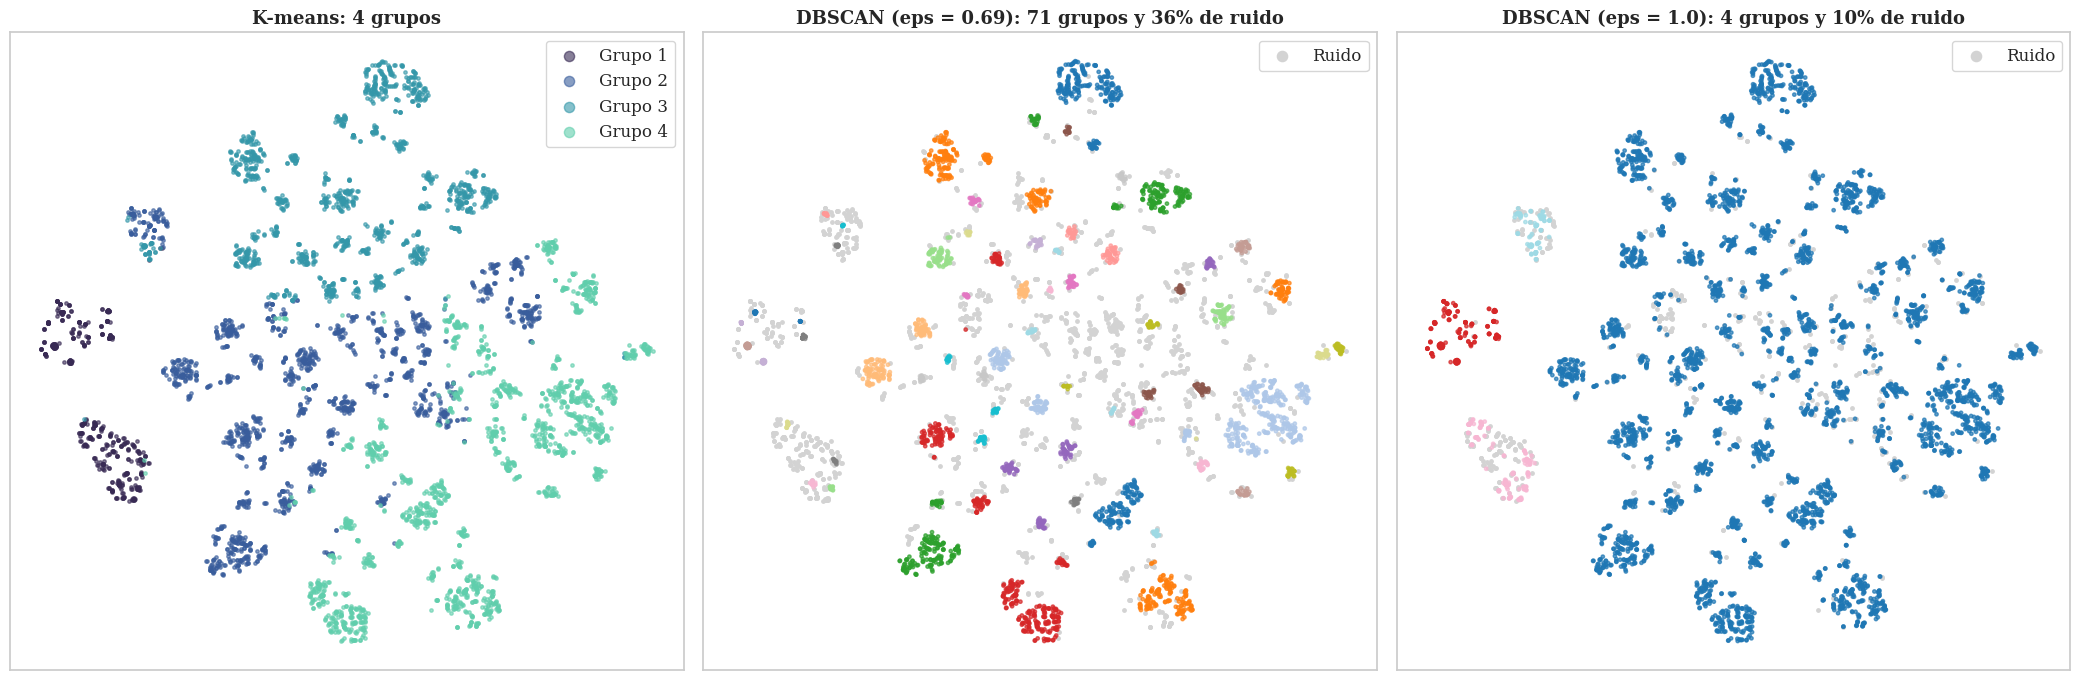

In [31]:
# DBSCAN con un eps pequeño y uno grande de la tabla del paso 7, sobre la misma muestra de 10 mil
eps_pequeno = resultados_dbscan["eps"].iloc[2]
eps_grande = resultados_dbscan["eps"].iloc[3]
etiquetas_dbscan = {
    eps_pequeno: DBSCAN(eps=eps_pequeno, min_samples=min_vecinos).fit(P_comparacion).labels_,
    eps_grande: DBSCAN(eps=eps_grande, min_samples=min_vecinos).fit(P_comparacion).labels_,
}

fig, axes = plt.subplots(1, 3, figsize=(21, 7))

# K-means como referencia (los 5 mil del t-SNE son los primeros 5 mil de la muestra de 10 mil)
for g in sorted(np.unique(grupos_tsne)):
    en_grupo = grupos_tsne == g
    axes[0].scatter(T[en_grupo, 0], T[en_grupo, 1], s=6, alpha=0.6, label=f"Grupo {g}",
                    color=sns.color_palette("mako", n_grupos)[g - 1])
axes[0].set_title(f"K-means: {n_grupos} grupos", fontsize=13, fontweight="bold")
axes[0].legend(frameon=True, markerscale=3)

# DBSCAN: el ruido en gris y cada grupo de un color
for ax, (eps, etiquetas) in zip(axes[1:], etiquetas_dbscan.items()):
    etiquetas_tsne = etiquetas[:5_000]
    ruido = etiquetas_tsne == -1
    ax.scatter(T[ruido, 0], T[ruido, 1], s=6, color="lightgray", label="Ruido")
    ax.scatter(T[~ruido, 0], T[~ruido, 1], s=6, alpha=0.7, c=etiquetas_tsne[~ruido], cmap="tab20")
    n_grupos_dbscan = len(set(etiquetas)) - (1 if -1 in etiquetas else 0)
    ax.set_title(f"DBSCAN (eps = {eps}): {n_grupos_dbscan} grupos y {(etiquetas == -1).mean():.0%} de ruido",
                 fontsize=13, fontweight="bold")
    ax.legend(frameon=True, markerscale=3)

for ax in axes:
    ax.set_xticks([])
    ax.set_yticks([])
plt.tight_layout()
plt.show()

**Resultados del t-SNE:**

- **Grupos de K-means:** los grupos ocupan zonas distintas del gráfico. El grupo 1 forma islas separadas de los demás a la izquierda, lo que confirma que los estudiantes sin información del hogar son muy distintos al resto. El grupo 3 queda arriba, el 2 a la izquierda y en el centro, y el 4 abajo y a la derecha, con algo de mezcla en los bordes entre los grupos 2 y 4. Se ven muchas islas pequeñas, que corresponden a estudiantes con las mismas respuestas o respuestas muy parecidas.
- **Puntaje:** dentro de cada isla se mezclan puntajes altos y bajos, y no hay una zona clara de puntajes altos. Hay algo más de puntajes altos a la derecha, donde está el grupo 4. Esto confirma que el perfil explica solo una parte del puntaje: estudiantes con el mismo perfil pueden tener puntajes muy distintos.

### **Comparación entre PCA y t-SNE**

**Resultados de la comparación:** los grupos se ven más separados en el t-SNE que en el gráfico de los dos primeros componentes del PCA. En el PCA solo se distinguen con claridad las franjas de los estudiantes que no responden (grupo 1), y el resto queda en una sola nube, porque esos dos componentes explican solo el 32% de la varianza. En el t-SNE también se ven separados los grupos 2, 3 y 4. Es decir, la separación de los grupos existe en los 19 componentes que usa K-means, pero no se alcanza a ver con solo dos componentes del PCA. En los dos gráficos se ve lo mismo sobre el puntaje: se mezcla dentro de cada zona.

**Decisión:** PCA es la técnica que se usa para el clustering, porque se puede interpretar, usa todos los datos y se puede aplicar a la prueba para medir el error del modelo en cada grupo. t-SNE solo complementa la visualización.

## **9. Evaluación del modelo por región y tipo de colegio (objetivos 2 y 3)**

Se responde la segunda parte de la pregunta de investigación: qué tan bien generaliza el modelo para Santander y para distintos tipos de colegio. Se usa el modelo final de la entrega 2 (HistGradientBoosting optimizado) y el **conjunto de prueba**, que no se usó en ninguna decisión.

**Subgrupos comparados:**
- **Objetivo 2:** Santander frente al resto del país.
- **Objetivo 3:** colegios oficiales frente a no oficiales, y zona urbana frente a rural.

**Métricas por subgrupo**:
- **RMSE y MAE:** qué tanto se equivoca el modelo en promedio.
- **Error promedio** (puntaje real − predicho): si es positivo, el modelo predice de menos para ese subgrupo; si es negativo, predice de más.
- **R² dentro del subgrupo:** qué parte de las diferencias de puntaje entre estudiantes del subgrupo explica el modelo.

El departamento no es una variable del modelo, así que el modelo trata igual a un estudiante de Santander que a uno de otro departamento con las mismas respuestas. Si el modelo se equivoca de forma distinta en Santander, hay algo de la región que las variables no capturan.

In [32]:
datos_test = df.loc[X_test.index]

# Subgrupos de cada comparación
subgrupos = {
    "Región": pd.Series(np.where(datos_test["cole_depto_ubicacion"].str.upper() == "SANTANDER",
                                 "Santander", "Resto del país"), index=X_test.index),
    "Naturaleza": datos_test["cole_naturaleza"].str.capitalize(),
    "Zona": datos_test["cole_area_ubicacion"].str.capitalize(),
}

# Métricas del modelo en cada subgrupo
filas = []
for comparacion, valores in subgrupos.items():
    for nombre in sorted(valores.unique()):
        en_subgrupo = valores == nombre
        real, pred = y_test[en_subgrupo], prediccion_test[en_subgrupo]
        filas.append({
            "Comparación": comparacion,
            "Subgrupo": nombre,
            "Estudiantes test": en_subgrupo.sum(),
            "Puntaje real promedio": real.mean(),
            "Puntaje predicho promedio": pred.mean(),
            "Error promedio": (real - pred).mean(),
            "RMSE": mean_squared_error(real, pred) ** 0.5,
            "MAE": mean_absolute_error(real, pred),
            "R2 dentro del subgrupo": r2_score(real, pred),
        })

error_por_subgrupo = pd.DataFrame(filas).set_index(["Comparación", "Subgrupo"]).round(3)
error_por_subgrupo

Estudiantes test  Puntaje real promedio  \
Comparación Subgrupo                                                  
Región      Resto del país            108573                255.967   
            Santander                   5262                274.785   
Naturaleza  No oficial                 29112                277.350   
            Oficial                    84723                249.788   
Zona        Rural                      19496                235.949   
            Urbana                     94339                261.153   

                            Puntaje predicho promedio  Error promedio    RMSE  \
Comparación Subgrupo                                                            
Región      Resto del país                    256.696          -0.730  43.969   
            Santander                         258.492          16.293  48.324   
Naturaleza  No oficial                        277.752          -0.402  45.116   
            Oficial                           249.573           0.215  43.853   
Zona        Rural                             236.282          -0.333  42.044   
            Urbana                            261.015           0.138  44.608   

                               MAE  R2 dentro del subgrupo  
Comparación Subgrupo                                        
Región      Resto del país  35.492                   0.355  
            Santander       38.901                   0.256  
Naturaleza  No oficial      36.139                   0.439  
            Oficial         35.482                   0.264  
Zona        Rural           33.667                   0.361  
            Urbana          36.060                   0.328

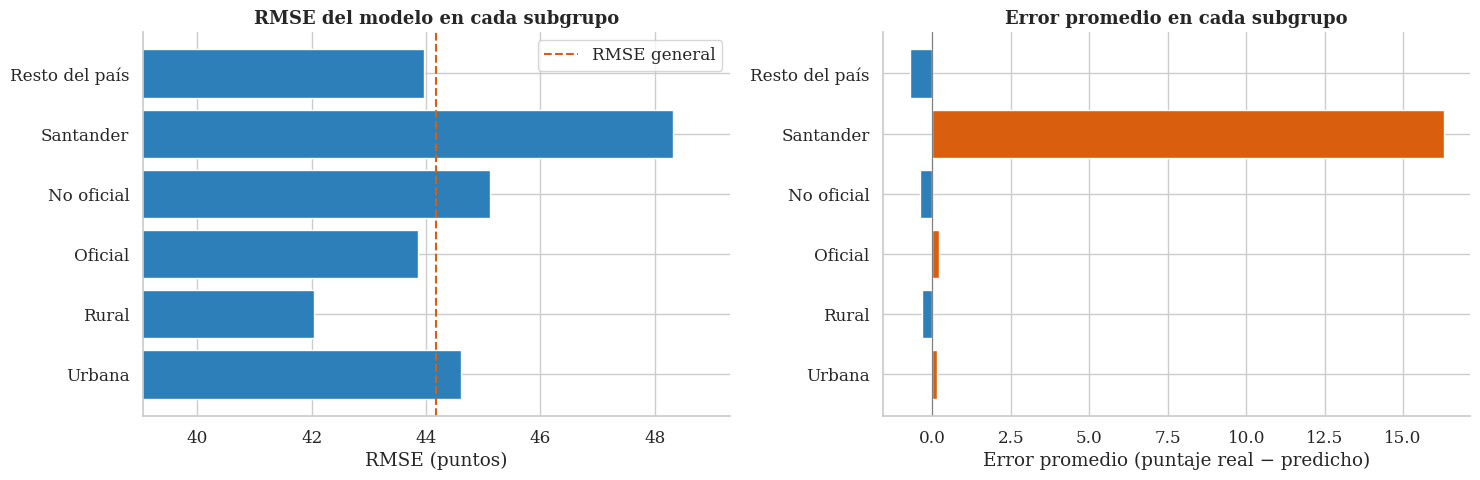

In [33]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
etiquetas = [f"{s}" for _, s in error_por_subgrupo.index]
posiciones = np.arange(len(etiquetas))

# RMSE de cada subgrupo frente al RMSE general
axes[0].barh(posiciones, error_por_subgrupo["RMSE"], color=color_acento)
axes[0].axvline(mean_squared_error(y_test, prediccion_test) ** 0.5, color=color_secundario,
                linestyle="--", label="RMSE general")
axes[0].set_xlim(error_por_subgrupo["RMSE"].min() - 3, error_por_subgrupo["RMSE"].max() + 1)
axes[0].set_xlabel("RMSE (puntos)")
axes[0].set_title("RMSE del modelo en cada subgrupo", fontsize=13, fontweight="bold")
axes[0].legend(frameon=True)

# Error promedio de cada subgrupo (positivo: el modelo predice de menos)
colores = [color_secundario if v > 0 else color_acento for v in error_por_subgrupo["Error promedio"]]
axes[1].barh(posiciones, error_por_subgrupo["Error promedio"], color=colores)
axes[1].axvline(0, color="gray", linewidth=0.8)
axes[1].set_xlabel("Error promedio (puntaje real − predicho)")
axes[1].set_title("Error promedio en cada subgrupo", fontsize=13, fontweight="bold")

for ax in axes:
    ax.set_yticks(posiciones)
    ax.set_yticklabels(etiquetas)
    ax.invert_yaxis()
sns.despine()
plt.tight_layout()
plt.show()

**Resultados del error por subgrupo:**

- **Santander frente al resto del país:** es la diferencia más grande. En Santander el RMSE es 48.32, frente a 43.97 en el resto del país, y el error promedio es de **+16.3 puntos**: el modelo predice de menos para Santander. Los estudiantes de Santander sacan en promedio 274.8 puntos, pero el modelo les predice 258.5. Además, el R² dentro de Santander es más bajo (0.256 frente a 0.355). Esto coincide con el paso 5: con el mismo perfil, los estudiantes de Santander sacan más que los del resto del país, y como el modelo no conoce el departamento, no puede saberlo.
- **Oficial y no oficial:** el RMSE es parecido (43.85 en oficiales y 45.12 en no oficiales) y el error promedio es casi 0 en los dos (0.22 y −0.40), así que no hay sesgo. El R² es mucho mayor en los no oficiales (0.439 frente a 0.264): entre colegios no oficiales, las variables distinguen mejor a quién le va mejor.
- **Urbano y rural:** el modelo se equivoca un poco menos en la zona rural (RMSE 42.04 frente a 44.61) y el error promedio es casi 0 en las dos (−0.33 y 0.14). El R² es parecido (0.361 y 0.328).

**Interpretación:** el modelo generaliza bien para los tipos de colegio y para la zona: el error es parecido y no tiene sesgo. La excepción es Santander, donde el modelo subestima el puntaje en 16 puntos en promedio. El modelo aprendió la relación entre las variables y el puntaje para todo el país, y en Santander los estudiantes sacan más de lo que esas variables predicen. Como Santander es solo el 4.6% de los estudiantes, ese sesgo casi no se nota en el error general.

### **Importancia de las variables por subgrupo**

**Método:** importancia por permutación. Para medir qué tanto usa el modelo una variable, se desordenan al azar sus valores entre los estudiantes (así la variable deja de tener relación con el puntaje) y se mide cuánto aumenta el RMSE. Si el RMSE aumenta mucho, la variable es importante para predecir en ese subgrupo; si casi no cambia, el modelo no depende de ella.

**Decisiones:**
- **Por variable completa:** igual que en la selección de características de la entrega 2, se desordenan juntas todas las columnas de cada variable (su nivel y sus indicadoras, o todas sus columnas one-hot). Desordenar cada columna one-hot por separado daría combinaciones imposibles, como un estudiante de dos jornadas a la vez.
- **En cada subgrupo del conjunto de prueba por separado**, para comparar si las variables importan igual en Santander que en el resto del país, en colegios oficiales que en no oficiales, y en zona urbana que en rural.
- **3 repeticiones** por variable, y se promedia el aumento del RMSE, porque el resultado depende de cómo se desordenen los valores.
- En los subgrupos con más de 20 mil estudiantes se usa una muestra de **20 mil**, para que el cálculo sea más rápido.

In [34]:
# Aumento del RMSE al desordenar cada variable en un grupo de estudiantes
def importancia_por_variable(X, y, repeticiones=3):
    generador = np.random.default_rng(SEMILLA)
    rmse_base = mean_squared_error(y, hgb_final.predict(X)) ** 0.5
    importancia = {}
    for variable in vars_seleccionadas:
        columnas = cols_por_variable[variable]
        aumentos = []
        for _ in range(repeticiones):
            X_desordenado = X.copy()
            orden = generador.permutation(len(X))
            # Todas las columnas de la variable se desordenan juntas
            X_desordenado[columnas] = X[columnas].to_numpy()[orden]
            rmse = mean_squared_error(y, hgb_final.predict(X_desordenado)) ** 0.5
            aumentos.append(rmse - rmse_base)
        importancia[variable] = np.mean(aumentos)
    return pd.Series(importancia)

X_te_modelo = X_test[cols_seleccionadas]
importancias = {}
for comparacion, valores in subgrupos.items():
    for nombre in sorted(valores.unique()):
        indices = valores[valores == nombre].index
        # Muestra de 20 mil estudiantes en los subgrupos grandes
        if len(indices) > 20_000:
            indices = pd.Index(np.random.default_rng(SEMILLA).choice(indices, 20_000, replace=False))
        importancias[nombre] = importancia_por_variable(X_te_modelo.loc[indices], y_test.loc[indices])
        print(f"{nombre}: listo ({len(indices):,} estudiantes)")

importancia_subgrupos = pd.DataFrame(importancias)
# Ordenar las variables por su importancia promedio
importancia_subgrupos = importancia_subgrupos.loc[
    importancia_subgrupos.mean(axis=1).sort_values(ascending=False).index]

Resto del país: listo (20,000 estudiantes)
Santander: listo (5,262 estudiantes)
No oficial: listo (20,000 estudiantes)
Oficial: listo (20,000 estudiantes)
Rural: listo (19,496 estudiantes)
Urbana: listo (20,000 estudiantes)


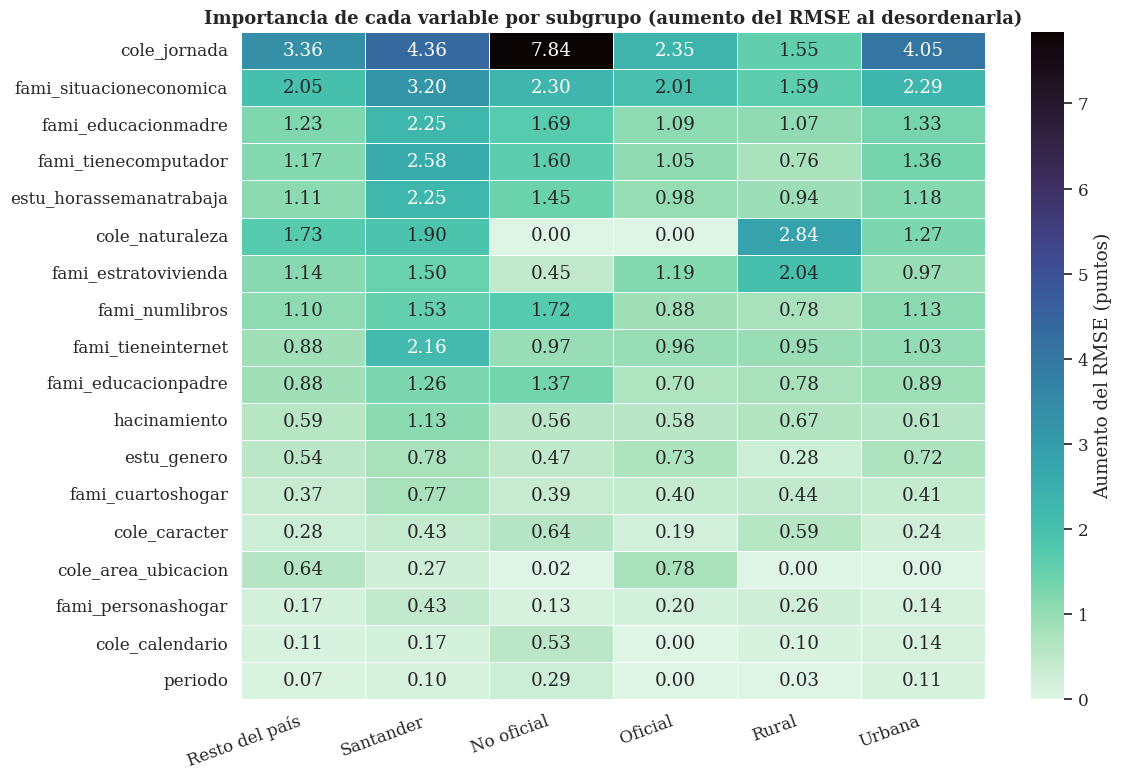

Posición de las 5 variables más importantes en cada subgrupo:


,Resto del país,Santander,No oficial,Oficial,Rural,Urbana
cole_jornada,1,1,1,1,4,1
fami_situacioneconomica,2,2,2,2,3,2
fami_educacionmadre,4,4,4,4,5,4
fami_tienecomputador,5,3,5,5,10,3
estu_horassemanatrabaja,7,5,6,6,7,6


In [35]:
fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(importancia_subgrupos, annot=True, fmt=".2f", cmap="mako_r",
            linewidths=0.6, linecolor="white",
            cbar_kws={"label": "Aumento del RMSE (puntos)"}, ax=ax)
ax.set_title("Importancia de cada variable por subgrupo (aumento del RMSE al desordenarla)",
             fontsize=13, fontweight="bold")
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

# Posición de cada variable en el ranking de cada subgrupo (1 = la más importante)
ranking_subgrupos = importancia_subgrupos.rank(ascending=False).astype(int)
print("Posición de las 5 variables más importantes en cada subgrupo:")
ranking_subgrupos.head(5)

**Resultados de la importancia por subgrupo:**

- **Variables más importantes en general:** la jornada es la más importante en casi todos los subgrupos (primera en todos excepto en la zona rural), seguida de la situación económica (segunda o tercera en todos), la educación de la madre, tener computador y las horas de trabajo. Una parte de la importancia de la situación económica puede venir de su indicadora de "No reporta", porque al desordenarla también se desordena si el estudiante respondió o no las preguntas del hogar.
- **Santander frente al resto del país:** el orden de las variables más importantes es casi el mismo (jornada, situación económica, educación de la madre, computador). La diferencia es que en Santander todas las variables aumentan más el RMSE al desordenarlas; por ejemplo, tener internet (2.16 frente a 0.88) y tener computador (2.58 frente a 1.17). Es decir, el modelo usa las mismas variables en Santander, pero el problema del paso anterior no es que las use de forma distinta, sino que a todos los estudiantes de Santander les predice de menos.
- **Oficial y no oficial:** en los colegios no oficiales la jornada pesa mucho más que en cualquier otro subgrupo (7.84, frente a 2.35 en los oficiales): entre colegios privados, la jornada es lo que más distingue a quién le va mejor. En los oficiales, las variables tienen una importancia más pareja y más baja, lo que coincide con su R² más bajo. La naturaleza del colegio tiene importancia 0 en los dos, porque dentro de cada subgrupo no varía.
- **Urbano y rural:** en la zona rural cambia el orden. Las más importantes son la naturaleza del colegio (2.84), el estrato (2.04) y la situación económica (1.59), mientras que la jornada baja al cuarto lugar y tener computador al décimo. En la zona urbana el orden es el general: jornada, situación económica y computador. El área tiene importancia 0 en los dos, porque dentro de cada subgrupo no varía.

**Interpretación:** las relaciones entre las variables y el puntaje son parecidas en Santander y en el resto del país, y entre colegios oficiales y no oficiales, aunque con distinta fuerza. La zona rural es el subgrupo donde más cambian: allí importa más si el colegio es oficial o no y el estrato, y menos tener computador. Un modelo entrenado solo con estudiantes rurales podría aprovechar mejor esas diferencias.

## **Conclusiones del aprendizaje no supervisado**

- **PCA:** el primer componente (20.6% de la varianza) separa a los estudiantes que no responden las preguntas del hogar de los que responden y tienen internet y computador, y tiene una correlación de 0.318 con el puntaje. El segundo (11.4%) separa el tipo de colegio de los recursos del hogar. Se necesitan 19 de 39 componentes para conservar el 90% de la varianza.
- **Grupos encontrados:** 4 grupos, elegidos con el método del codo y la silueta: estudiantes sin información del hogar (9.4%), oficiales con pocos recursos (31.7%), oficiales de jornada única (25.6%) y hogares con más recursos (33.2%). La silueta es baja (0.166), así que los grupos se traslapan: los perfiles cambian de forma gradual.
- **Puntaje por grupo:** el grupo con más recursos saca 37 puntos más que el grupo sin información del hogar (276.2 frente a 238.8), pero los puntajes se traslapan mucho, porque la desviación dentro de cada grupo (50 a 57 puntos) es mayor que la diferencia entre grupos.
- **Santander y tipo de colegio:** Santander tiene un perfil parecido al del resto del país, pero saca entre 11 y 23 puntos más en todos los grupos, así que su diferencia no se explica solo por el perfil. Los colegios no oficiales se concentran en el grupo de más recursos (68%) y la zona rural en el de menos recursos (45%).
- **Error del modelo:** el modelo de la entrega 2 se equivoca de forma parecida en todos los grupos (RMSE entre 42.0 y 45.7) y no tiene sesgo en ninguno (error promedio cercano a 0). Se equivoca un poco más con los estudiantes sin información del hogar.
- **Algoritmo elegido:** K-means, porque tiene mayor silueta que Agglomerative Clustering (0.164 frente a 0.128) y los dos encuentran 4 grupos y coinciden en dos de ellos, mientras que DBSCAN no forma grupos útiles con datos categóricos. Además, es el único que puede usar todo el entrenamiento y asignar grupos a la prueba.
- **Error del modelo:** el modelo de la entrega 2 se equivoca de forma parecida en todos los grupos (RMSE entre 42.0 y 45.7): ninguno se aleja más de 2.2 puntos de su RMSE general (44.18). Además, no tiene sesgo en ninguno (error promedio cercano a 0). Se equivoca un poco más con los estudiantes sin información del hogar (45.7) y menos con los de colegios oficiales con pocos recursos (42.0).

**Ideas para mejorar el modelo a futuro:**
- **Estudiantes sin información del hogar:** es el grupo con más error. Se podrían usar fuentes externas que no dependan de la encuesta, como los índices socioeconómicos del colegio o del municipio, para tener información de estos estudiantes.
- **Diferencias regionales:** Santander saca más puntaje que el resto del país con el mismo perfil. Agregar variables del colegio o del municipio (por ejemplo, el desempeño histórico del colegio) podría capturar esas diferencias que el perfil del estudiante no explica.
- **Diferencias dentro de cada grupo:** el R² dentro de los grupos es bajo (entre 0.20 y 0.37), sobre todo en el grupo 3. Las variables actuales no alcanzan a distinguir a los estudiantes de un mismo perfil, así que para mejorar el modelo se necesitan variables nuevas, no nuevas combinaciones de las mismas.

## **Conclusiones generales del proyecto**

**Pregunta de investigación:** ¿Se puede predecir el puntaje global del Saber 11 2025 a partir de variables socioeconómicas y escolares, y qué tan bien generaliza el modelo para Santander y para distintos tipos de colegio?

- **¿Se puede predecir el puntaje?** Sí, pero de forma moderada. El mejor modelo, HistGradientBoosting optimizado, tiene un RMSE de 44.18 y un R² de 0.353 en el conjunto de prueba: las variables socioeconómicas y escolares explican alrededor de un tercio de las diferencias de puntaje. Supera a la regresión lineal (RMSE 46.00) y a la red neuronal (RMSE 44.36). Ninguna variable por sí sola explica más del 13% del puntaje, y las más relacionadas son la educación de los padres, la jornada, el número de libros y tener computador.
- **Objetivo 1:** los faltantes no son al azar (quienes no responden sacan menos), así que se trataron como la categoría "No reporta". Con información mutua se seleccionaron 18 de las 19 variables. El aprendizaje no supervisado confirmó que no responder las preguntas del hogar es una de las características que más diferencia a los estudiantes, y encontró 4 perfiles con puntajes promedio entre 239 y 276.
- **Objetivo 2 (Santander):** el modelo se equivoca más en Santander (RMSE 48.32 frente a 43.97) y le predice en promedio 16 puntos menos de lo que sacan sus estudiantes. Las variables más importantes son las mismas que en el resto del país (jornada, situación económica, educación de la madre y computador), así que el modelo no usa las variables de forma distinta en Santander: lo que pasa es que los estudiantes de Santander sacan más de lo que predicen sus variables. Con el mismo perfil, los estudiantes de Santander sacan entre 11 y 23 puntos más que los del resto del país (parte 5).
- **Objetivo 3 (tipo de colegio y zona):** el modelo se equivoca de forma parecida en colegios oficiales y no oficiales (RMSE 43.85 y 45.12) y en zona urbana y rural (44.61 y 42.04), sin sesgo en ninguno. En los no oficiales la jornada es mucho más importante que en el resto, y en la zona rural cambia el orden de las variables: importan más la naturaleza del colegio y el estrato, y menos tener computador. Los colegios no oficiales se concentran en el perfil con más recursos (68%) y la zona rural en el de menos recursos (45%) (parte 5).
- **Generalización:** el modelo generaliza bien para los tipos de colegio, la zona y los perfiles de K-means: el error cambia pocos puntos entre ellos y no tiene sesgo. Es menos confiable en Santander, donde subestima el puntaje, y en los estudiantes sin información del hogar, donde el error es un poco mayor.

**Limitaciones:**
- El modelo solo usa variables del estudiante, su hogar y su colegio que vienen de la encuesta del ICFES. No conoce otras cosas que influyen en el puntaje, como la calidad de los docentes, la preparación para el examen o la motivación del estudiante. Por eso el R² no pasa de 0.35.
- Se usaron solo los datos de 2025, así que no se sabe si el modelo funciona igual en otros años. (Recomendación de Fabio)

## **Aplicación práctica**

**Uso propuesto:** una herramienta para que las secretarías de educación (por ejemplo, la de Santander) **identifiquen colegios con riesgo de bajo puntaje** antes del examen. Con las respuestas de la encuesta socioeconómica que los estudiantes llenan al inscribirse, el modelo estima el puntaje esperado de cada estudiante y, promediando, el de cada colegio. Así se pueden focalizar apoyos (refuerzo académico, simulacros, dotación de computadores) en los colegios donde más se necesitan. Los perfiles de K-means ayudan a decidir qué tipo de apoyo dar: por ejemplo, los estudiantes del perfil "oficial con pocos recursos" necesitan apoyos distintos a los de colegios no oficiales.

No se propone para decidir sobre estudiantes individuales (por ejemplo, admisiones o becas), porque el error de 44 puntos es demasiado grande para una sola persona y el modelo reflejaría las desigualdades socioeconómicas en lugar del esfuerzo del estudiante. Al promediar por colegio, el error se reduce.

**Retos técnicos para implementarlo:**
1. **Estudiantes sin información:** el 10% de los estudiantes no responde las preguntas del hogar y el modelo se equivoca más con ellos (perfil 1). Habría que completar su información con fuentes externas, como los índices socioeconómicos del colegio o del municipio.
2. **Actualización del modelo:** el modelo se entrenó con 2025. Las condiciones cambian cada año (por ejemplo, más hogares con internet), así que habría que volver a entrenarlo con cada nueva prueba y revisar que el error no aumente.
3. **Diferencias regionales:** el modelo subestima en 16 puntos el puntaje de los estudiantes de Santander (paso 9), porque aprendió con todo el país. Una secretaría departamental tendría que ajustar el modelo con sus propios datos, o agregar variables del colegio y del municipio que capturen esas diferencias.

**Viabilidad:** es viable técnicamente, porque los datos ya se recogen en la inscripción al examen, son públicos y el modelo se entrena y predice en pocos minutos. Su valor está en ordenar a los colegios según su necesidad de apoyo, no en predecir el puntaje exacto de cada estudiante.